# new

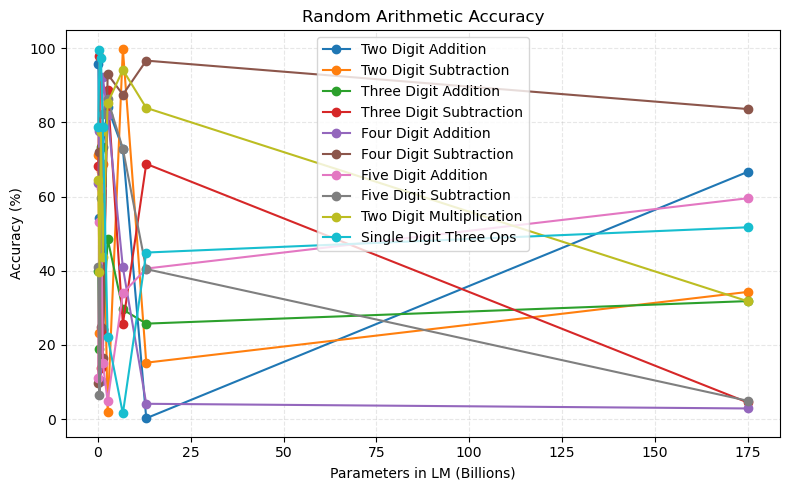

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Define model sizes and series names
x = [0.1, 0.4, 0.8, 1.3, 2.6, 6.7, 13, 175]
series_names = [
    'Two Digit Addition', 'Two Digit Subtraction', 'Three Digit Addition',
    'Three Digit Subtraction', 'Four Digit Addition', 'Four Digit Subtraction',
    'Five Digit Addition', 'Five Digit Subtraction', 'Two Digit Multiplication',
    'Single Digit Three Ops'
]

# Generate random accuracy data (0-100)
data = np.random.rand(len(x), len(series_names)) * 100

# Plot each series
plt.figure(figsize=(8, 5))
for i, name in enumerate(series_names):
    plt.plot(x, data[:, i], marker='o', label=name)

plt.xlabel('Parameters in LM (Billions)')
plt.ylabel('Accuracy (%)')
plt.title('Random Arithmetic Accuracy')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

(2,)


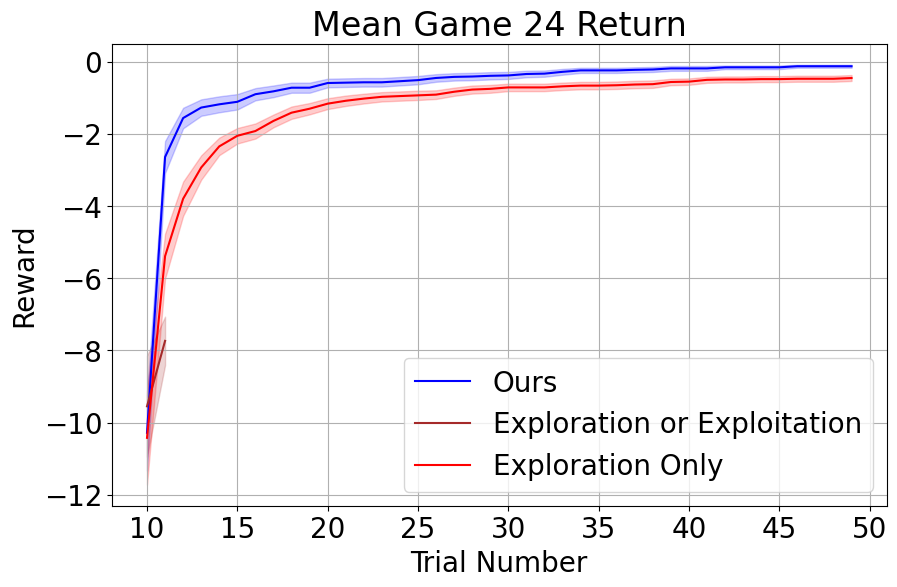

In [31]:
plt.rcParams['font.size'] = 20


# May 11th
from scipy.ndimage import gaussian_filter

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_step_wise_reward_100_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_step_wise_reward_100_e&e_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"


running_max = True

max_round = 50
start_round = 10

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1]) + start_round

# 2
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"

# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1]) + start_round

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_3_demo_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_3demo2_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1]) + start_round

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_ICRL_gpt4.1__evalnum_40_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1]) + start_round

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_llm_as_optimizer_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)
# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)

smoothed= 1
if smoothed: 
    mean_rewards_5 = gaussian_filter(mean_rewards_5, sigma=1)




standard_error = std_rewards / np.sqrt(n)
print(standard_error.shape)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1]) + start_round




second = 1
third = 0
fourth = 0
fifth = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards[:], 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='Exploration or Exploitation')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'orange', label='Zero Reward')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='orange', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'red', label='Exploration Only')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='red', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)

    

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Game 24 Return')
plt.legend(loc='lower right')
plt.grid(True)


plt.savefig('figures/game24_return_ablation.pdf', format='pdf', bbox_inches='tight')

plt.show()

(49,)
(49,)
(49,)


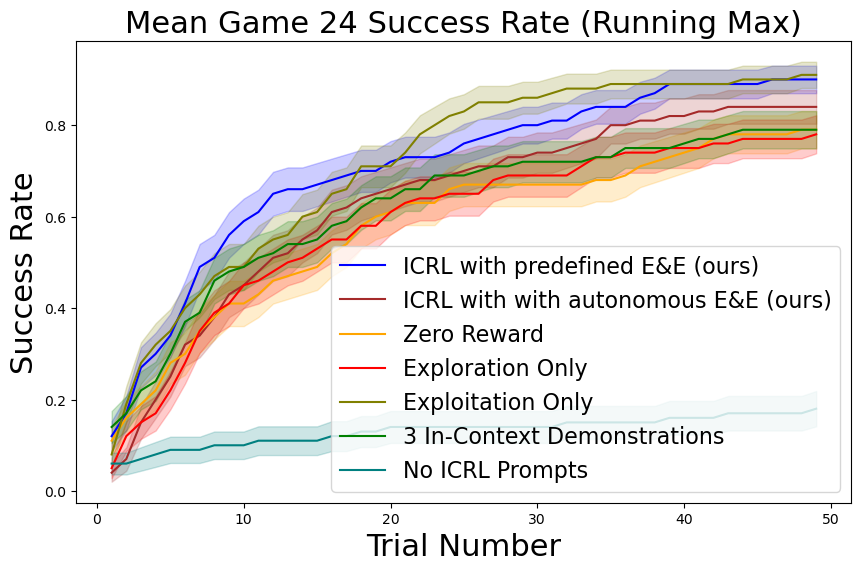

In [6]:
# May 11th
from scipy.ndimage import gaussian_filter

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_step_wise_reward_100_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_step_wise_reward_100_e&e_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_simple_prompting_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"

running_max = True

max_round = 50
start_round = 1

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1]) + start_round

# 2
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1]) + start_round

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_3_demo_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_3demo2_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1]) + start_round

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_ICRL_gpt4.1__evalnum_40_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1]) + start_round

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)
# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)

smoothed= 0
if smoothed: 
    mean_rewards_5 = gaussian_filter(mean_rewards_5, sigma=1)




standard_error = std_rewards / np.sqrt(n)
print(standard_error.shape)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1]) + start_round

# 6

path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_no_ICRL_prompting_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_6 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)
# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)

smoothed= 0
if smoothed: 
    mean_rewards_6 = gaussian_filter(mean_rewards_6, sigma=1)




standard_error = std_rewards / np.sqrt(n)
print(standard_error.shape)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_6 = mean_rewards_6 - standard_error
upper_bound_6 = mean_rewards_6 + standard_error

# Generate x values (trial indices)
x_6 = np.arange(data.shape[1]) + start_round


# 7

path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_exploitation_only_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_llm_as_optimizer_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_7 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)
# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)

smoothed= 0
if smoothed: 
    mean_rewards_7 = gaussian_filter(mean_rewards_7, sigma=1)




standard_error = std_rewards / np.sqrt(n)
print(standard_error.shape)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_7 = mean_rewards_7 - standard_error
upper_bound_7 = mean_rewards_7 + standard_error

# Generate x values (trial indices)
x_7 = np.arange(data.shape[1]) + start_round


second = 1
third = 1
fourth = 1
fifth = 1
sixth = 1


# second = 0
# third = 0
# fourth = 0
# fifth = 0
# sixth = 0
seventh = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards[:], 'b-', label='ICRL with predefined E&E (ours)')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='ICRL with with autonomous E&E (ours)')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'orange', label='Zero Reward')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='orange', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'red', label='Exploration Only')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='red', alpha=0.2)
if seventh:
    plt.plot(x_7, mean_rewards_7, 'olive', label='Exploitation Only')
    plt.fill_between(x_7, lower_bound_7, upper_bound_7, color='olive', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
    
if sixth:
    plt.plot(x_6, mean_rewards_6, 'teal', label='No ICRL Prompts')
    plt.fill_between(x_6, lower_bound_6, upper_bound_6, color='teal', alpha=0.2)

# 'blue', 'purple', 'cyan', 'magenta', 'pink', 'black', 'gray', 'olive', 'navy', 'teal'

plt.xlabel('Trial Number', fontsize=22)
plt.ylabel('Success Rate', fontsize= 22)
plt.title('Mean Game 24 Success Rate (Running Max)', fontsize=22)
plt.legend(loc='lower right', fontsize=16)
plt.grid(False)

# plt.rcParams['font.size'] = 26



plt.savefig('figures/game24_return_ablation_running_max.pdf', format='pdf', bbox_inches='tight')

plt.show()

(49,)


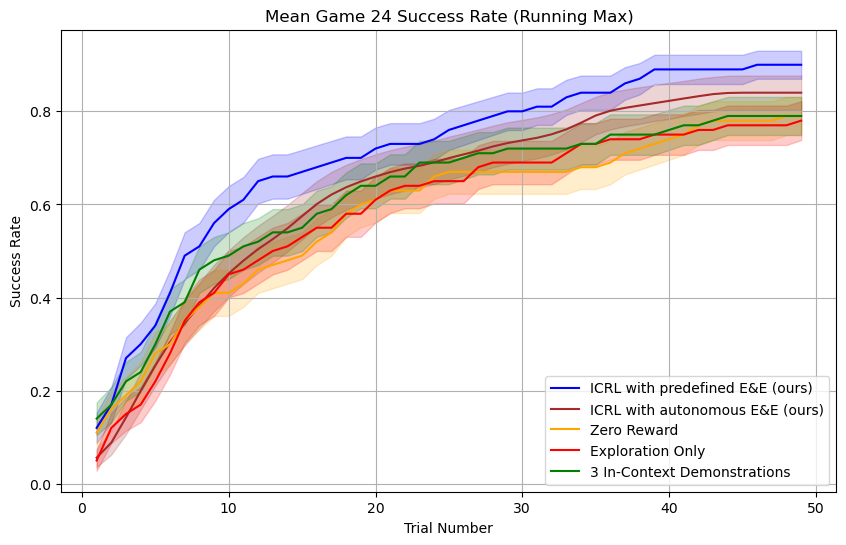

In [1]:
# May 11th
from scipy.ndimage import gaussian_filter

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_step_wise_reward_100_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_step_wise_reward_100_e&e_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
running_max = True

max_round = 50
start_round = 1

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1]) + start_round

# 2
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1]) + start_round

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_3_demo_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_3demo2_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1]) + start_round

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_ICRL_gpt4.1__evalnum_40_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1]) + start_round

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)
# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)

smoothed= 1
if smoothed: 
    mean_rewards_5 = gaussian_filter(mean_rewards_5, sigma=1)




standard_error = std_rewards / np.sqrt(n)
print(standard_error.shape)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1]) + start_round




second = 1
third = 1
fourth = 1
fifth = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards[:], 'b-', label='ICRL with predefined E&E (ours)')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='ICRL with autonomous E&E (ours)')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'orange', label='Zero Reward')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='orange', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'red', label='Exploration Only')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='red', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)

    

plt.xlabel('Trial Number')
plt.ylabel('Success Rate')
plt.title('Mean Game 24 Success Rate (Running Max)')
plt.legend(loc='lower right')
plt.grid(True)


plt.savefig('figures/game24_return_ablation_running_max.pdf', format='pdf', bbox_inches='tight')

plt.show()

In [102]:
df = pd.DataFrame(mean_rewards_5)
df_smoothed = df.apply(lambda x: gaussian_filter(x, sigma=1))

In [5]:
# df_smoothed

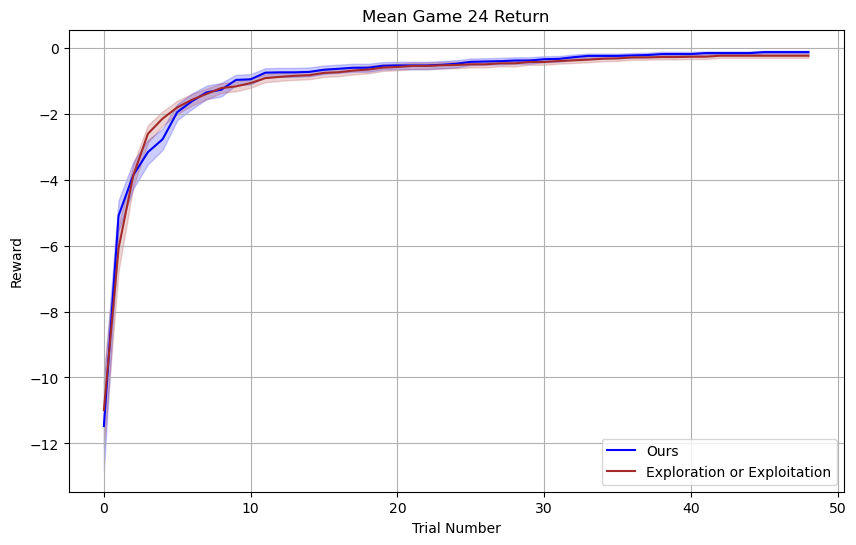

In [52]:
# May 4rd

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_step_wise_reward_100_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_step_wise_reward_100_e&e_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:50]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_3_demo_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"



with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_ICRL_gpt4.1__evalnum_40_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])




second = 0
third = 0
fourth = 0
fifth = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='Exploration or Exploitation')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'orange', label='Zero Reward')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='orange', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'red', label='Exploration Only')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='red', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)

    
    
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Game 24 Return')
plt.legend(loc='lower right')
plt.grid(True)


plt.savefig('figures/game24_return_ablation.pdf', format='pdf', bbox_inches='tight')

plt.show()

/home/ks8vf/.local/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1741: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)


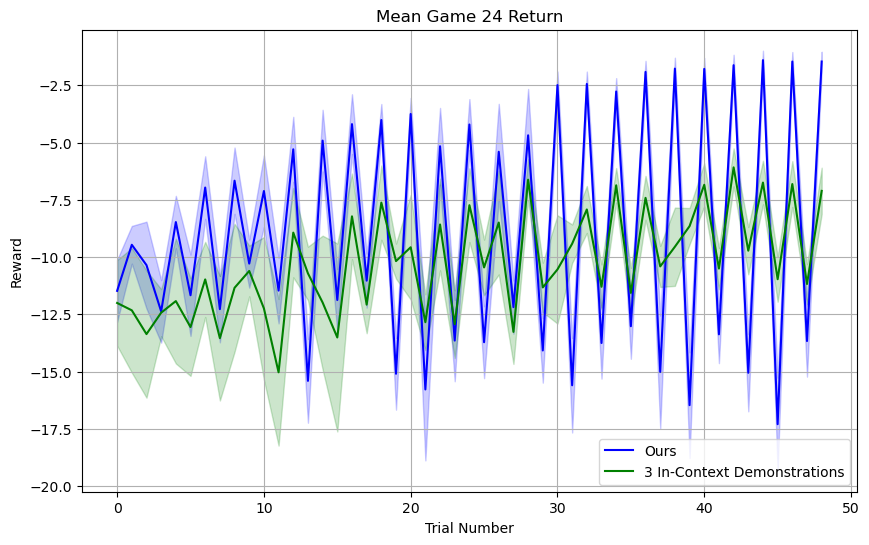

In [51]:
# May 4rd

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_step_wise_reward_100_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_step_wise_reward_100_e&e_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
running_max = False

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:50]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_3_demo_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"



with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_ICRL_gpt4.1__evalnum_40_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])




second = 0
third = 1
fourth = 0
fifth = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='Exploration or Exploitation')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'orange', label='Zero Reward')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='orange', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'red', label='Exploration Only')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='red', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)

    
    
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Game 24 Return')
plt.legend(loc='lower right')
plt.grid(True)


plt.savefig('figures/game24_return_ablation.pdf', format='pdf', bbox_inches='tight')

plt.show()

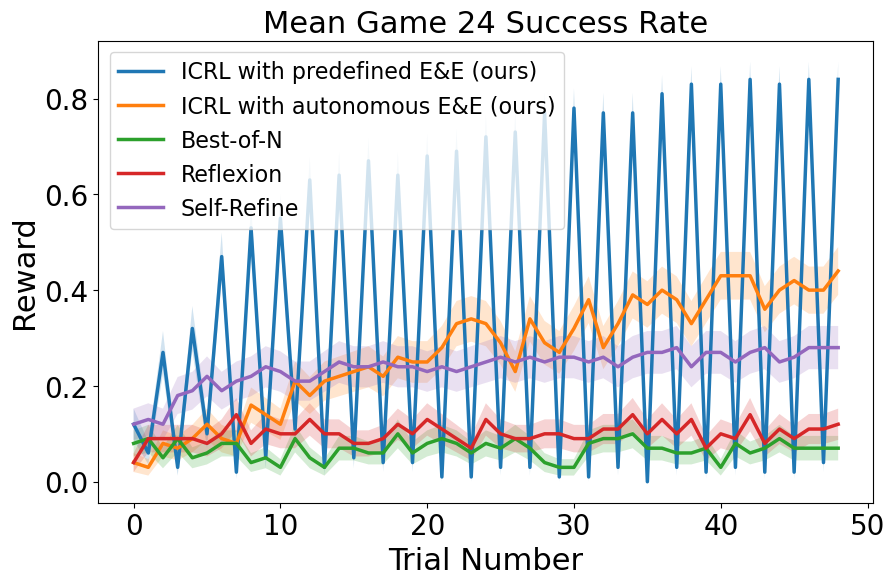

In [28]:
# May 4rd

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"

running_max = False

import matplotlib.colors as mcolors


plt.rcParams.update({
    'font.size': 10,  # Base font size
    # 'axes.titlesize': 36,  # Title font size
    'axes.labelsize': 30,  # Axis label font size
    'xtick.labelsize': 20,  # X-axis tick label size
    'ytick.labelsize': 20,  # Y-axis tick label size
    'legend.fontsize': 36,  # Legend font size
    # 'figure.titlesize': 54  # Figure title size
    'lines.linewidth': 2.5,    # Default line width for all plots
    "figure.figsize": (10, 10),
    # 'axes.xmargin': 0,  # remove x-axis data margin
    # 'legend.handlelength': 3,  # Length of legend handles
    # 'legend.handleheight': 1.5,  # Height of legend handles
    # 'legend.linewidth': 3,     # Line width in legend
})


import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:50]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_strong_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)
data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/rejection_100_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_1_self_refine_ICRL_4.1_evalnum_1_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_self-refine_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_self-refine_few_shot_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_correct_self-refine_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_long_CoT_stronger_reward_only_ICRL_4.1_evalnum_100_n_1/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_CoT_reward_only_ICRL_4.1_evalnum_100_n_1/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])




second = 1
third = 1
fourth = 1
fifth = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, label='ICRL with predefined E&E (ours)')
plt.fill_between(x, lower_bound, upper_bound, alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, label='ICRL with autonomous E&E (ours)')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3,  label='Best-of-N')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion,  label='Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion,  alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4,  label='Self-Refine')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, alpha=0.2)


    
plt.xlabel('Trial Number', fontsize=22)
plt.ylabel('Reward', fontsize=22)
plt.title('Mean Game 24 Success Rate', fontsize=22)
plt.legend(loc='upper left', fontsize=16)
plt.grid(False)

plt.savefig('figures/game24_return.pdf', format='pdf', bbox_inches='tight')

plt.show()

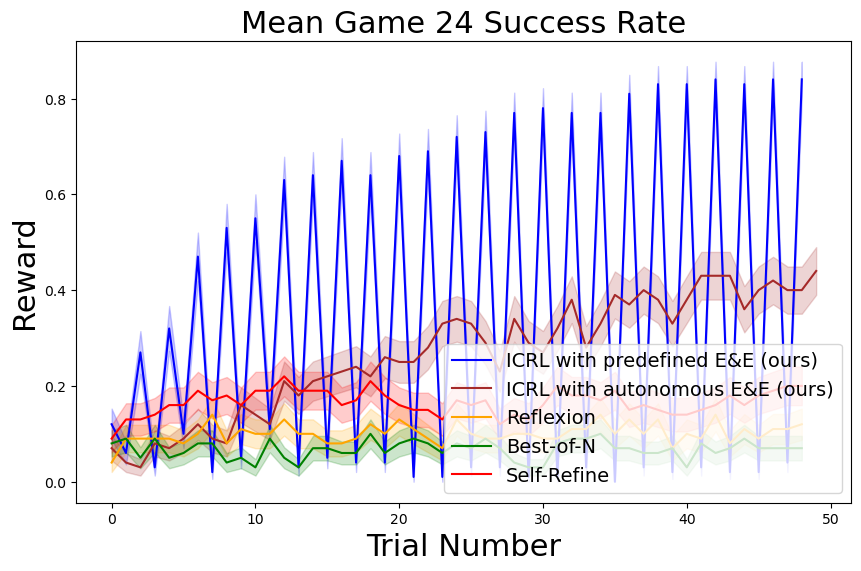

In [8]:
# May 4rd

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"

running_max = False

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:50]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_strong_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)
data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/rejection_100_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_1_self_refine_ICRL_4.1_evalnum_1_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_self-refine_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_self-refine_few_shot_ICRL_4.1_evalnum_100_n_50/output_list.json"
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_long_CoT_stronger_reward_only_ICRL_4.1_evalnum_100_n_1/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_CoT_reward_only_ICRL_4.1_evalnum_100_n_1/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])





second = 1
third = 1
fourth = 1
fifth = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='ICRL with predefined E&E (ours)')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='ICRL with autonomous E&E (ours)')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='Best-of-N')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'red', label='Self-Refine')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='red', alpha=0.2)
    
    
plt.xlabel('Trial Number', fontsize=22)
plt.ylabel('Reward', fontsize=22)
plt.title('Mean Game 24 Success Rate', fontsize=22)
plt.legend(loc='lower right', fontsize=16)
plt.grid(False)

plt.savefig('figures/game24_return.pdf', format='pdf', bbox_inches='tight')

plt.show()

In [85]:
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_CoT_reward_only_ICRL_4.1_evalnum_100_n_1/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

In [86]:
np.mean(np.array(modified_data).reshape(-1)==0)

0.06

In [42]:
np.mean(np.array(modified_data).reshape(-1) == 0)

0.47

In [43]:
mean_rewards_5

array([-6.36])

In [41]:
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

In [ ]:
# all_question_reward_list

In [ ]:
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"


/home/ks8vf/.local/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1741: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)


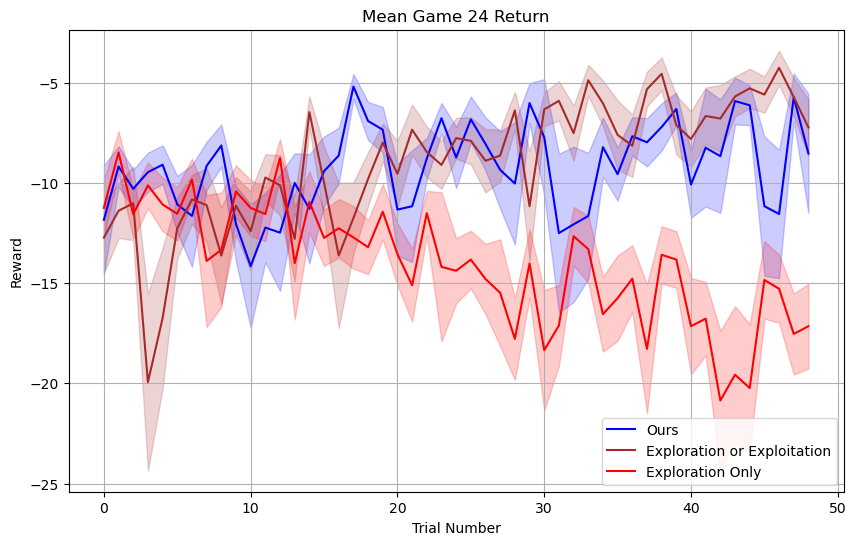

In [12]:
# May 4rd

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_step_wise_reward_100_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_step_wise_reward_100_e&e_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_15/output_list.json"
running_max = False

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:50]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_ICRL_gpt4.1__evalnum_40_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])




second = 1
third = 0
fourth = 0
fifth = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='Exploration or Exploitation')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'orange', label='Zero Reward')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='orange', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'red', label='Exploration Only')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='red', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)

    
    
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Game 24 Return')
plt.legend(loc='lower right')
plt.grid(True)


plt.savefig('figures/game24_return_ablation.pdf', format='pdf', bbox_inches='tight')

plt.show()

# plots

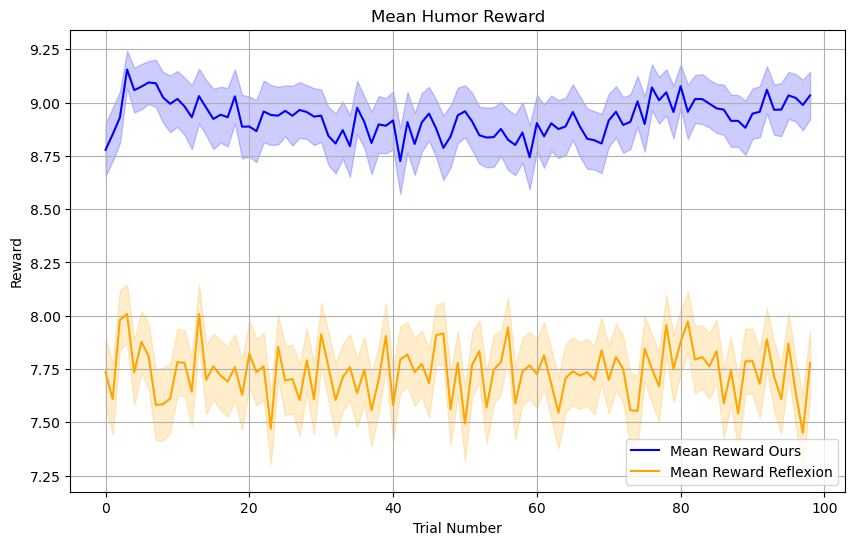

In [267]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_humor/meta-llama/Meta-Llama-3-8B-Instruct/two_rewards4.1mini_n_100/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open('alpaca_humor/meta-llama/Meta-Llama-3-8B-Instruct/rejection_two_rewards4.1mini_n_100/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])



# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

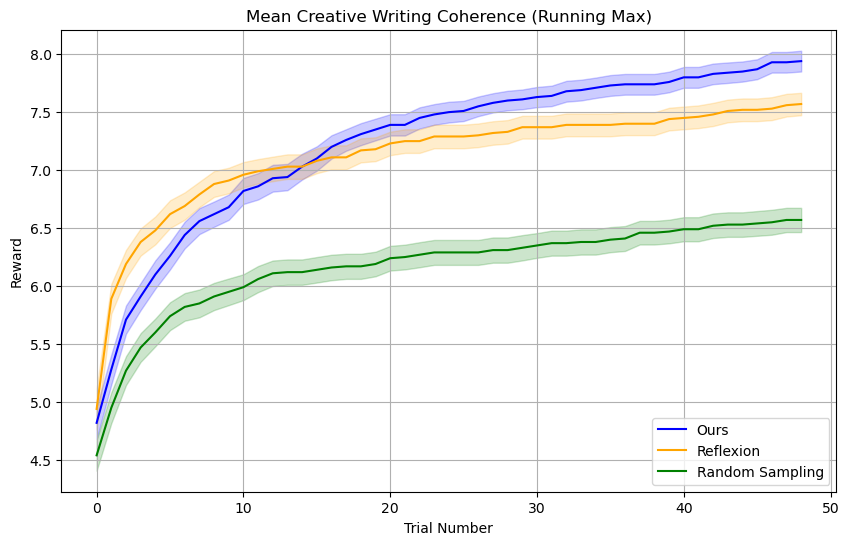

In [25]:
# May 4rd

path = "creative_writing_api/google/gemma-7b-it/ICRL_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

path = "creative_writing_api/google/gemma-7b-it/reflexion_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"


# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

# ### 3

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])


path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])



second = 1
third = 1
fourth = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='Random Sampling')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'red', label='Exploration only')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='red', alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Creative Writing Coherence (Running Max)')
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig('figures/creative_writing_coherence_running_max.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [99]:
path = "creative_writing_api/google/gemma-7b-it/ICRL_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

In [105]:
ours_score

array([9., 8., 8., 8., 8., 6., 9., 4., 9., 8., 8., 9., 9., 8., 8., 7., 7.,
       8., 7., 9., 8., 9., 7., 9., 7., 9., 8., 8., 8., 7., 7., 8., 8., 9.,
       7., 7., 7., 9., 9., 9., 9., 7., 8., 7., 7., 8., 8., 9., 8., 7., 9.,
       7., 8., 8., 9., 7., 6., 9., 8., 7., 7., 8., 9., 8., 9., 8., 8., 9.,
       9., 7., 9., 8., 8., 7., 8., 8., 8., 8., 8., 7., 8., 9., 8., 8., 7.,
       8., 7., 8., 8., 8., 8., 6., 8., 8., 9., 9., 8., 7., 9., 9.])

In [100]:
ours_score = modified_data[:, -1]

In [101]:
running_max = True
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/reflexion_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

In [102]:
reflexion_score = modified_data[:, -1]

In [106]:
reflexion_score

array([8., 8., 7., 8., 7., 7., 8., 3., 8., 6., 8., 8., 8., 8., 8., 8., 7.,
       9., 7., 9., 7., 8., 9., 7., 8., 7., 8., 8., 8., 6., 7., 7., 7., 9.,
       7., 6., 7., 7., 8., 8., 9., 7., 7., 7., 7., 7., 8., 8., 8., 7., 9.,
       7., 9., 8., 8., 7., 8., 8., 8., 4., 9., 7., 9., 8., 8., 7., 8., 7.,
       9., 6., 9., 8., 7., 8., 8., 7., 8., 8., 8., 8., 7., 8., 8., 7., 7.,
       8., 6., 8., 8., 6., 8., 6., 8., 8., 8., 8., 8., 7., 8., 8.])

In [109]:
np.sum(ours_score > reflexion_score)

42

In [110]:
np.sum(ours_score < reflexion_score)

10

In [112]:
np.sum(ours_score == reflexion_score)

48

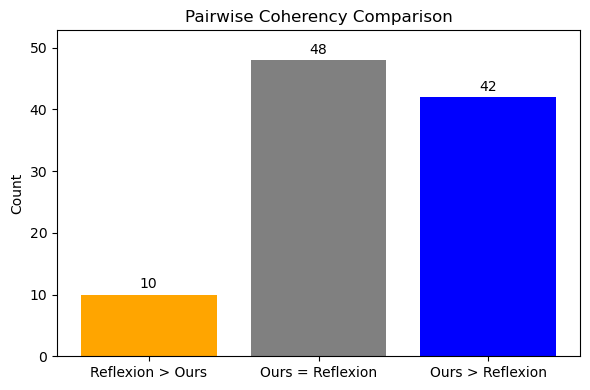

In [184]:
import matplotlib.pyplot as plt

# Data
categories = ['Reflexion > Ours', 'Ours = Reflexion', 'Ours > Reflexion']
values = [10, 48, 42]
colors = ["orange", "gray", "blue"]

# Plot
plt.figure(figsize=(6, 4))
bars = plt.bar(categories, values, color = colors)
for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 1, str(v), ha='center')

plt.ylim(0, max(values) * 1.1)
plt.ylabel('Count')
plt.title('Pairwise Coherency Comparison')
plt.tight_layout()
plt.savefig('figures/pairwise_comparison_ours_reflexion.pdf', format='pdf', bbox_inches='tight')
plt.show()

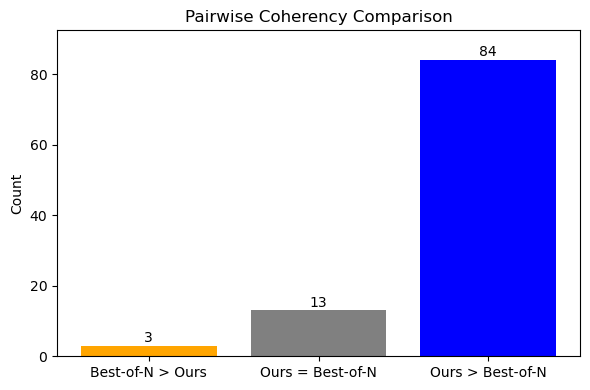

In [185]:
import matplotlib.pyplot as plt

# Data
categories = ['Best-of-N > Ours', 'Ours = Best-of-N', 'Ours > Best-of-N']
values = [3, 13, 84]
colors = ["orange", "gray", "blue"]

# Plot
plt.figure(figsize=(6, 4))
bars = plt.bar(categories, values, color = colors)
for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 1, str(v), ha='center')

plt.ylim(0, max(values) * 1.1)
plt.ylabel('Count')
plt.title('Pairwise Coherency Comparison')
plt.tight_layout()
plt.savefig('figures/pairwise_comparison_ours_best_of_n.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [113]:
running_max = True
path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/reflexion_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

In [114]:
best_of_n_score = modified_data[:, -1]

In [120]:
np.sum(ours_score > best_of_n_score)

84

In [121]:
np.sum(ours_score < best_of_n_score)

3

In [123]:
np.sum(ours_score == best_of_n_score)

13

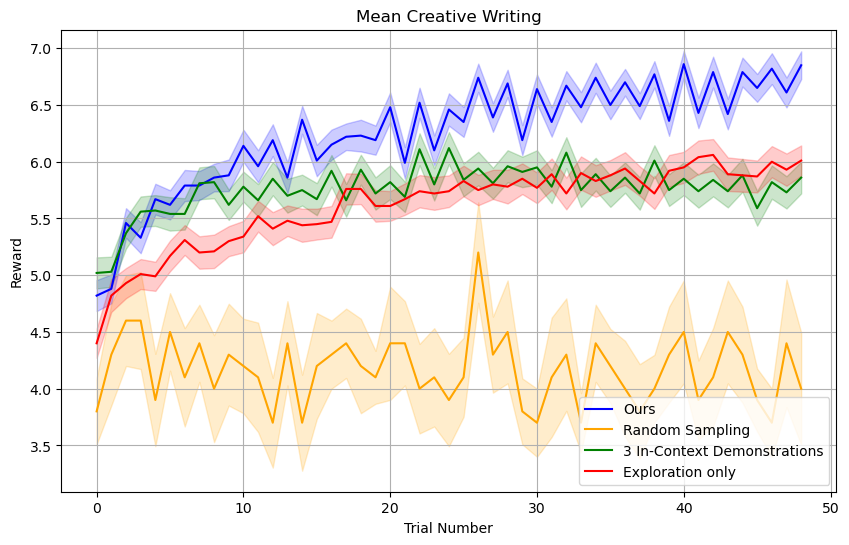

In [275]:
# May 4rd

path = "creative_writing_api/google/gemma-7b-it/ICRL_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

running_max = False

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])


path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:10]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# ### 3

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])


path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])



second = 1
third = 1
fourth = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Random Sampling')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'red', label='Exploration only')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='red', alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Creative Writing')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Creative Writing Ablation Study

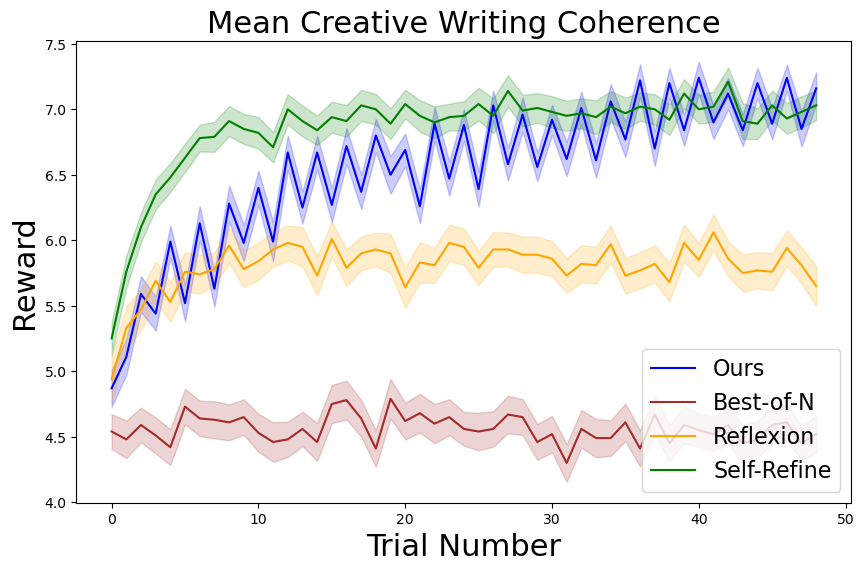

In [16]:
# May 4rd

# 1
path = "creative_writing_api/google/gemma-7b-it/ICRL_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_prompting_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_prompt_long_iterations_100_gpt_4.1_same_base_evalnum_100_n_100/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_prompt_long_iterations_continued_100_gpt_4.1_same_base_evalnum_100_n_51/output_list.json"
running_max = False
max_round = 50
import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
# 98
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:max_round]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row if x != 1] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_zero_reward_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/reflexion_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/reflexion_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:max_round]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3

path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_formatted100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_70_continued100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:max_round]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row if x != 1] for row in all_question_reward_list]
### Running max


if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_formatted100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:max_round]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])


# 5
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:max_round]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])

# 6
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploitation_only_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_continue100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_70_continued100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:max_round]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_6 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_6 = mean_rewards_6 - standard_error
upper_bound_6 = mean_rewards_6 + standard_error

# Generate x values (trial indices)
x_6 = np.arange(data.shape[1])

# 7
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_no_ICRL_prompting_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:max_round]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_7 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_7 = mean_rewards_7 - standard_error
upper_bound_7 = mean_rewards_7 + standard_error

# Generate x values (trial indices)
x_7 = np.arange(data.shape[1])



second = 1
third = 1
fourth = 0
fifth = 1
sixth = 0
seventh = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='Best-of-N')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='Self-Refine')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'red', label='self-refine2')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='red', alpha=0.2)
if sixth: 
    plt.plot(x_6, mean_rewards_6, 'teal', label='self-refine continued')
    plt.fill_between(x_6, lower_bound_6, upper_bound_6, color='teal', alpha=0.2)
    
if seventh: 
    plt.plot(x_7, mean_rewards_7, 'olive', label='No ICRL Prompt')
    plt.fill_between(x_7, lower_bound_7, upper_bound_7, color='olive', alpha=0.2)


plt.xlabel('Trial Number', fontsize=22)
plt.ylabel('Reward', fontsize=22)
plt.title('Mean Creative Writing Coherence', fontsize=22)
plt.legend(loc='lower right', fontsize=16)
plt.grid(False)
plt.savefig('figures/creative_writing_ablation_running_max.pdf', format='pdf', bbox_inches='tight')
plt.show()

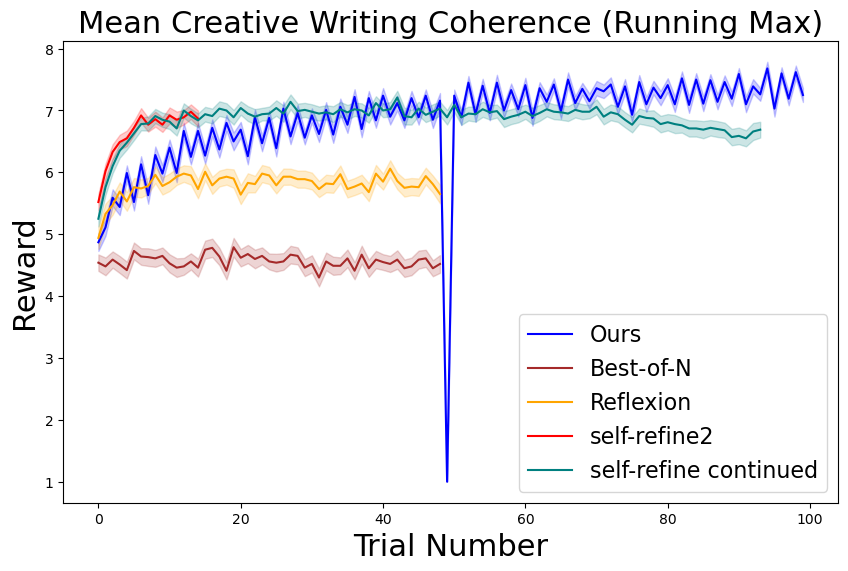

In [41]:
# May 4rd

# 1
path = "creative_writing_api/google/gemma-7b-it/ICRL_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_prompting_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_prompt_long_iterations_100_gpt_4.1_same_base_evalnum_100_n_100/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_prompt_long_iterations_continued_100_gpt_4.1_same_base_evalnum_100_n_51/output_list.json"
running_max = False

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row ] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_zero_reward_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/reflexion_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/reflexion_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3

path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_formatted100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max


if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_formatted100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])


# 5
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])

# 6
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploitation_only_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_continue100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_70_continued100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row if x != 1] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_6 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_6 = mean_rewards_6 - standard_error
upper_bound_6 = mean_rewards_6 + standard_error

# Generate x values (trial indices)
x_6 = np.arange(data.shape[1])

# 7
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_no_ICRL_prompting_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_7 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_7 = mean_rewards_7 - standard_error
upper_bound_7 = mean_rewards_7 + standard_error

# Generate x values (trial indices)
x_7 = np.arange(data.shape[1])



second = 1
third = 0
fourth = 1
fifth = 1
sixth = 1
seventh = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='Best-of-N')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='Self-Refine')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'red', label='self-refine2')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='red', alpha=0.2)
if sixth: 
    plt.plot(x_6, mean_rewards_6, 'teal', label='self-refine continued')
    plt.fill_between(x_6, lower_bound_6, upper_bound_6, color='teal', alpha=0.2)
    
if seventh: 
    plt.plot(x_7, mean_rewards_7, 'olive', label='No ICRL Prompt')
    plt.fill_between(x_7, lower_bound_7, upper_bound_7, color='olive', alpha=0.2)


plt.xlabel('Trial Number', fontsize=22)
plt.ylabel('Reward', fontsize=22)
plt.title('Mean Creative Writing Coherence (Running Max)', fontsize=22)
plt.legend(loc='lower right', fontsize=16)
plt.grid(False)
plt.savefig('figures/creative_writing_ablation_running_max.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [32]:
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_70_continued100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
    
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row if x != 1] for row in all_question_reward_list]

In [31]:
for i in range(200):
    print(np.sum([np.array(modified_data) == 1][0][i]))

2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2


IndexError: index 100 is out of bounds for axis 0 with size 100

In [88]:
# path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/self_refine_done_right_continue100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
with open(path, 'r') as f:
    output = json.load(f)


In [92]:
len(output[0])

52

In [96]:
len(output[0][-10]['prompt'])

205170

In [ ]:
# May 4rd

# 1
path = "creative_writing_api/google/gemma-7b-it/ICRL_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_prompting_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_zero_reward_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/reflexion_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3

path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])


# 5
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])

# 6
path = "creative_writing_api/google/gemma-7b-it/ICRL_exploitation_only_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_6 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_6 = mean_rewards_6 - standard_error
upper_bound_6 = mean_rewards_6 + standard_error

# Generate x values (trial indices)
x_6 = np.arange(data.shape[1])

# 7
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_no_ICRL_prompting_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_7 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_7 = mean_rewards_7 - standard_error
upper_bound_7 = mean_rewards_7 + standard_error

# Generate x values (trial indices)
x_7 = np.arange(data.shape[1])



second = 1
third = 1
fourth = 1
fifth = 1
sixth = 1
seventh = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='Exploration or Exploitation')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Zero Reward')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'red', label='Exploration Only')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='red', alpha=0.2)
if sixth: 
    plt.plot(x_6, mean_rewards_6, 'teal', label='Exploitation Only')
    plt.fill_between(x_6, lower_bound_6, upper_bound_6, color='teal', alpha=0.2)
    
if seventh: 
    plt.plot(x_7, mean_rewards_7, 'olive', label='No ICRL Prompt')
    plt.fill_between(x_7, lower_bound_7, upper_bound_7, color='olive', alpha=0.2)


plt.xlabel('Trial Number', fontsize=22)
plt.ylabel('Reward', fontsize=22)
plt.title('Mean Creative Writing Coherence (Running Max)', fontsize=22)
plt.legend(loc='lower right', fontsize=16)
plt.grid(False)
plt.savefig('figures/creative_writing_ablation_running_max.pdf', format='pdf', bbox_inches='tight')
plt.show()

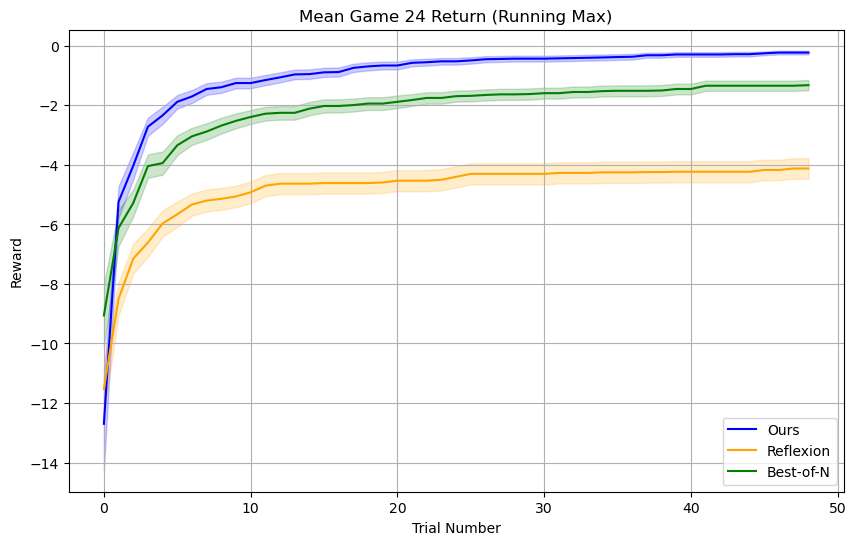

In [150]:
# May 4rd

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"

running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:50]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/rejection_100_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])




second = 1
third = 1
fourth = 0
fifth = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='Best-of-N')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'red', label='No Reward')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='red', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='Exploration or Exploitation')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
    
    
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Game 24 Return (Running Max)')
plt.legend(loc='lower right')
plt.grid(True)

plt.savefig('figures/game24_return_running_max.pdf', format='pdf', bbox_inches='tight')

plt.show()

# game of 24

(47,)
(49,)
(49,)


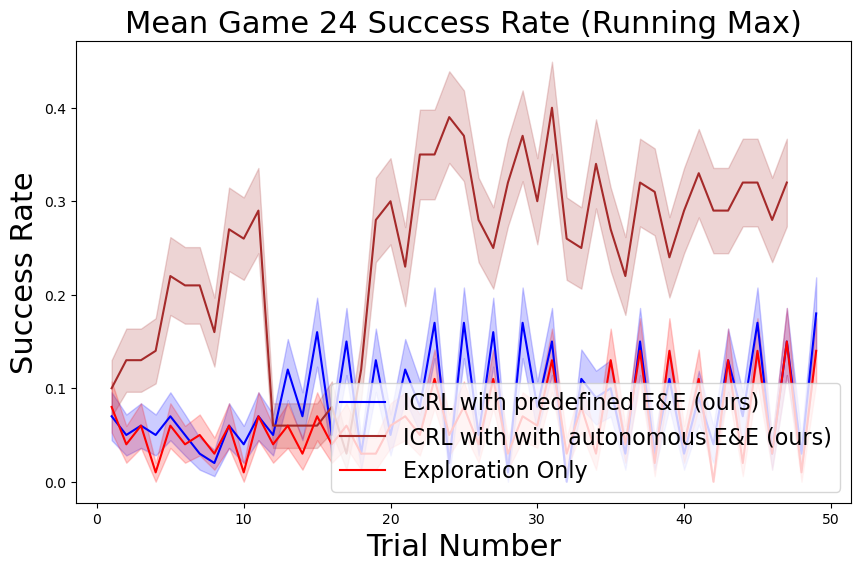

In [23]:
# July 28th
from scipy.ndimage import gaussian_filter

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_step_wise_reward_100_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_step_wise_reward_100_e&e_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_simple_prompting_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "/sfs/weka/scratch/ks8vf/code_submission/ICL/alpaca_game24_api/Qwen/Qwen3-32B/ICRL_no_think_evalnum_100_n_51/output_list.json"

running_max = False

max_round = 50
start_round = 1

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1]) + start_round

# 2
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# ### Rejection 
path = "/sfs/weka/scratch/ks8vf/code_submission/ICL/alpaca_game24_api/Qwen/Qwen3-32B/ICRL_no_think_evalnum_100_n_51/output_list.json"
path = "/sfs/weka/scratch/ks8vf/code_submission/ICL/alpaca_game24_api/Qwen/Qwen3-32B/ICRL_evalnum_100_n_51/output_list.json"
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

data = data == 0

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1]) + start_round

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_3_demo_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_3demo2_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "/sfs/weka/scratch/ks8vf/code_submission/ICL/alpaca_game24_api/Qwen/Qwen3-32B/ICRL_no_think_evalnum_100_n_51/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1]) + start_round

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_ICRL_gpt4.1__evalnum_40_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "/sfs/weka/scratch/ks8vf/code_submission/ICL/alpaca_game24_api/Qwen/Qwen3-32B/ICRL_no_think_evalnum_100_n_51/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1]) + start_round

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "/sfs/weka/scratch/ks8vf/code_submission/ICL/alpaca_game24_api/Qwen/Qwen3-32B/4.1_eval_100_strong_reflexion_ICRL_4.1_evalnum_45_n_51/output_list.json"
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)
# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)

smoothed= 0
if smoothed: 
    mean_rewards_5 = gaussian_filter(mean_rewards_5, sigma=1)




standard_error = std_rewards / np.sqrt(n)
print(standard_error.shape)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1]) + start_round

# 6

path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_no_ICRL_prompting_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "/sfs/weka/scratch/ks8vf/code_submission/ICL/alpaca_game24_api/Qwen/Qwen3-32B/ICRL_no_think_evalnum_100_n_51/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_6 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)
# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)

smoothed= 0
if smoothed: 
    mean_rewards_6 = gaussian_filter(mean_rewards_6, sigma=1)




standard_error = std_rewards / np.sqrt(n)
print(standard_error.shape)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_6 = mean_rewards_6 - standard_error
upper_bound_6 = mean_rewards_6 + standard_error

# Generate x values (trial indices)
x_6 = np.arange(data.shape[1]) + start_round


# 7

path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_exploitation_only_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_llm_as_optimizer_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "/sfs/weka/scratch/ks8vf/code_submission/ICL/alpaca_game24_api/Qwen/Qwen3-32B/ICRL_no_think_evalnum_100_n_51/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_round:max_round]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)


data = data == 0
# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_7 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)
# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)

smoothed= 0
if smoothed: 
    mean_rewards_7 = gaussian_filter(mean_rewards_7, sigma=1)




standard_error = std_rewards / np.sqrt(n)
print(standard_error.shape)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_7 = mean_rewards_7 - standard_error
upper_bound_7 = mean_rewards_7 + standard_error

# Generate x values (trial indices)
x_7 = np.arange(data.shape[1]) + start_round


second = 1
third = 0
fourth = 0
fifth = 1
sixth = 0


# second = 0
# third = 0
# fourth = 0
# fifth = 0
# sixth = 0
seventh = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards[:], 'b-', label='ICRL with predefined E&E (ours)')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='ICRL with with autonomous E&E (ours)')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'orange', label='Zero Reward')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='orange', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'red', label='Exploration Only')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='red', alpha=0.2)
if seventh:
    plt.plot(x_7, mean_rewards_7, 'olive', label='Exploitation Only')
    plt.fill_between(x_7, lower_bound_7, upper_bound_7, color='olive', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
    
if sixth:
    plt.plot(x_6, mean_rewards_6, 'teal', label='No ICRL Prompts')
    plt.fill_between(x_6, lower_bound_6, upper_bound_6, color='teal', alpha=0.2)

# 'blue', 'purple', 'cyan', 'magenta', 'pink', 'black', 'gray', 'olive', 'navy', 'teal'

plt.xlabel('Trial Number', fontsize=22)
plt.ylabel('Success Rate', fontsize= 22)
plt.title('Mean Game 24 Success Rate (Running Max)', fontsize=22)
plt.legend(loc='lower right', fontsize=16)
plt.grid(False)

# plt.rcParams['font.size'] = 26



# plt.savefig('figures/game24_return_ablation_running_max.pdf', format='pdf', bbox_inches='tight')

plt.show()

In [47]:
path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_Ours_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_e&e3_reward_only_ICRL_4.1_evalnum_100_n_50/output_list.json"

running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:50]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

In [48]:
modified_data

array([[ -1.,  -1.,  -1., ...,   0.,   0.,   0.],
       [-12.,  -1.,  -1., ...,   0.,   0.,   0.],
       [-12.,  -8.,  -2., ...,   0.,   0.,   0.],
       ...,
       [ -9.,   0.,   0., ...,   0.,   0.,   0.],
       [  0.,   0.,   0., ...,   0.,   0.,   0.],
       [-14., -12.,   0., ...,   0.,   0.,   0.]])

In [ ]:
# ours: 0.9
# e&e: 0.84
# reflexion: 0.44
# best-of-n: 0.49
# self-refine: 0.47
# long-cot: 0.47


In [49]:
np.mean(np.array(modified_data)[:, -1] == 0)

0.84

In [54]:
running_max = True 
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_strong_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

In [55]:
# modified_data[:, -1]

In [56]:
np.mean(np.array(modified_data)[:, -1] == 0)

0.44

In [67]:
running_max = True
path = "alpaca_game24_api/google/gemma-7b-it/rejection_100_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_100_self-refine_few_shot_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/4.1_eval_long_CoT_stronger_reward_only_ICRL_4.1_evalnum_100_n_1/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

In [69]:
# modified_data

In [70]:
np.mean(np.array(modified_data)[:, -1] == 0)

0.47

/home/ks8vf/.local/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1741: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)


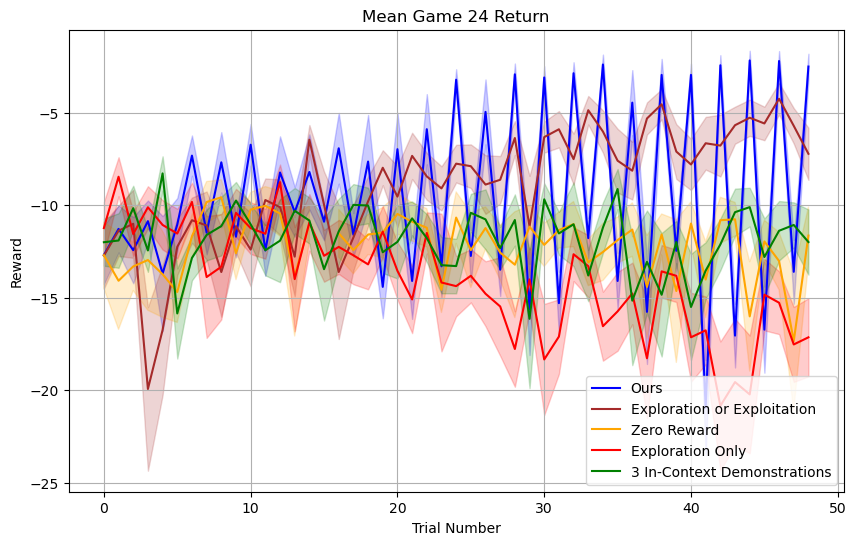

In [166]:
# May 4rd

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"

running_max = False

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:50]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_ICRL_gpt4.1__evalnum_40_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])




second = 1
third = 1
fourth = 1
fifth = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='Exploration or Exploitation')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'orange', label='Zero Reward')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='orange', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'red', label='Exploration Only')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='red', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)

    
    
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Game 24 Return')
plt.legend(loc='lower right')
plt.grid(True)


plt.savefig('figures/game24_return_ablation.pdf', format='pdf', bbox_inches='tight')

plt.show()

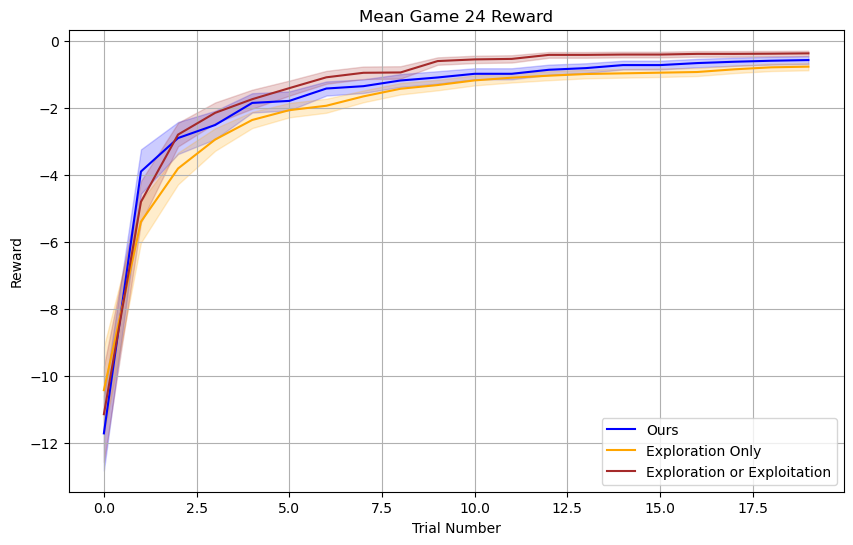

In [25]:
# May 4rd
max_trials = 30
start_trial = 10

path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"

running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_trial:max_trials]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# 2
# path = "creative_writing_api/google/gemma-7b-it/best_of_n_100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/100_reflexion_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_zero_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_trial:max_trials]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

# 3
# path = "creative_writing_api/google/gemma-7b-it/ICRL_3_demos100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_or_exploitation100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_3weak_demos_ICRL_4.1_evalnum_100_n_50/output_list.json"


with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_trial:max_trials]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

# 4
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_no_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_no_reward100_gpt_4.1_same_base_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_trial:max_trials]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_4 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_4 = mean_rewards_4 - standard_error
upper_bound_4 = mean_rewards_4 + standard_error

# Generate x values (trial indices)
x_4 = np.arange(data.shape[1])

# 5

path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_100_exploration_or_exploitation_ICRL_4.1_evalnum_100_n_50/output_list.json"

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[start_trial:max_trials]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_5 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_5 = mean_rewards_5 - standard_error
upper_bound_5 = mean_rewards_5 + standard_error

# Generate x values (trial indices)
x_5 = np.arange(data.shape[1])




second = 1
third = 0
fourth = 0
fifth = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Exploration Only')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='3 In-Context Demonstrations')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
if fourth: 
    plt.plot(x_4, mean_rewards_4, 'red', label='No Reward')
    plt.fill_between(x_4, lower_bound_4, upper_bound_4, color='red', alpha=0.2)
if fifth: 
    plt.plot(x_5, mean_rewards_5, 'brown', label='Exploration or Exploitation')
    plt.fill_between(x_5, lower_bound_5, upper_bound_5, color='brown', alpha=0.2)
    
    
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Game 24 Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

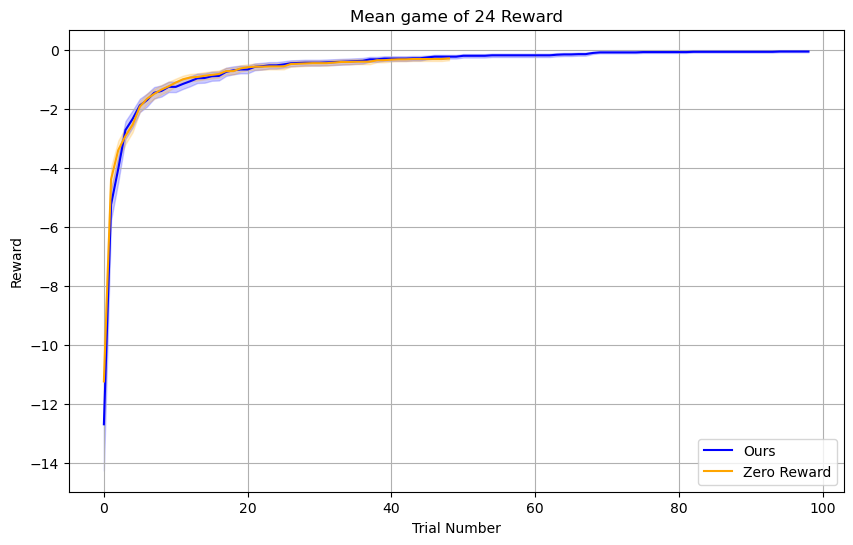

In [292]:
# May 3rd

path = "alpaca_game24_api/google/gemma-7b-it/1_samples_ICRL_step_wise_reward_4.1_mini_evalnum_10_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/new_p2_ICRL_step_wise_reward_4.1_mini_evalnum_10_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_wise_reward_ICRL_4.1_evalnum_10_n_20/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step1_wise_reward_ICRL_4.1_evalnum_10_n_50/output_list.json"

path = "alpaca_game24_api/google/gemma-7b-it/step2_original_prompt_wise_reward_ICRL_4.1_evalnum_10_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step2_100_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step2_100_original_prompt_wise_reward_ICRL_4.1-mini_evalnum_100_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/step_100_3explore_1exploit_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# path = "creative_writing_api/google/gemma-7b-it/best_of_n_same_base_evalnum_12_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_mini_evalnum_45_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_mini_evalnum_45_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_no_reward_exploration_only_100_mini_evalnum_45_n_100/output_list.json"
# this one is slightly incorrect as it includes reward
path = "alpaca_game24_api/google/gemma-7b-it/step_100_original_prompt_wise_reward_ICRL_no_reward_exploration_4.1_evalnum_100_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/step_100_no_reward_exploration_only_original_prompt_wise_reward_ICRL_4.1_evalnum_100_n_50/output_list.json"
# ### 3

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

second = 1
third = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Zero Reward')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='Exploration only')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='orange', alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean game of 24 Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [143]:
# data[54]

In [125]:

# # path = "alpaca_game24_api/google/gemma-7b-it/100_mini_evalnum_45_n_200/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_same_base_evalnum_12_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_exploitation_same_base_evalnum_12_n_100/output_list.json"

# running_max = False

# import numpy as np
# import matplotlib.pyplot as plt

# import json
# with open(path, 'r') as f:
#     output = json.load(f)
    
# all_question_reward_list = []
# for question in output[:]:
#     reward_list = []
#     for trial in question[1:]:
#         reward_list.append(float(trial['reward']))
#     all_question_reward_list.append(reward_list)
# modified_data = [[ x for x in row] for row in all_question_reward_list]
# ### Running max
# if running_max:
#     modified_data = np.maximum.accumulate(modified_data, axis=1)


# # None if x == -0.8 else
# # Assuming modified_data is already defined with None values for entries > 0.8
# all_question_reward_list = modified_data

# # Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# # Calculate the mean reward for each trial ignoring NaNs
# mean_rewards = np.nanmean(data, axis=0)

# # Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
# std_rewards = np.nanstd(data, axis=0, ddof=1)

# # For each trial, count the number of non-NaN values to compute the standard error
# n = np.sum(~np.isnan(data), axis=0)
# standard_error = std_rewards / np.sqrt(n)

# # Calculate lower and upper bounds (mean ± standard error)
# lower_bound = mean_rewards - standard_error
# upper_bound = mean_rewards + standard_error

# # Generate x values (trial indices)
# x = np.arange(data.shape[1])

# path = "creative_writing_api/google/gemma-7b-it/best_of_n_same_base_evalnum_12_n_100/output_list.json"
# # ### Rejection 

# with open(path, 'r') as f:
#     output = json.load(f)
    
# all_question_reward_list = []
# for question in output[:]:
#     reward_list = []
#     for trial in question[1:]:
#         reward_list.append(float(trial['reward']))
#     all_question_reward_list.append(reward_list)
# modified_data = [[x for x in row] for row in all_question_reward_list]
# ### Running max
# if running_max:
#     modified_data = np.maximum.accumulate(modified_data, axis=1)

# # Assuming modified_data is already defined with None values for entries > 0.8
# all_question_reward_list = modified_data

# # Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# # data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# # Calculate the mean reward for each trial ignoring NaNs
# mean_rewards_reflexion = np.nanmean(data, axis=0)

# # Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
# std_rewards = np.nanstd(data, axis=0, ddof=1)

# # For each trial, count the number of non-NaN values to compute the standard error
# n = np.sum(~np.isnan(data), axis=0)
# standard_error = std_rewards / np.sqrt(n)

# # Calculate lower and upper bounds (mean ± standard error)
# lower_bound_reflexion = mean_rewards_reflexion - standard_error
# upper_bound_reflexion = mean_rewards_reflexion + standard_error

# # Generate x values (trial indices)
# x_reflexion = np.arange(data.shape[1])


# second = 1
# # Create the plot
# plt.figure(figsize=(10, 6))
# plt.plot(x, mean_rewards, 'b-', label='Mean Rejection Sampling 24 Ours')
# plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
# if second:
#     plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
#     plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
# plt.xlabel('Trial Number')
# plt.ylabel('Reward')
# plt.title('Mean game of 24 Reward')
# plt.legend(loc='lower right')
# plt.grid(True)
# plt.show()

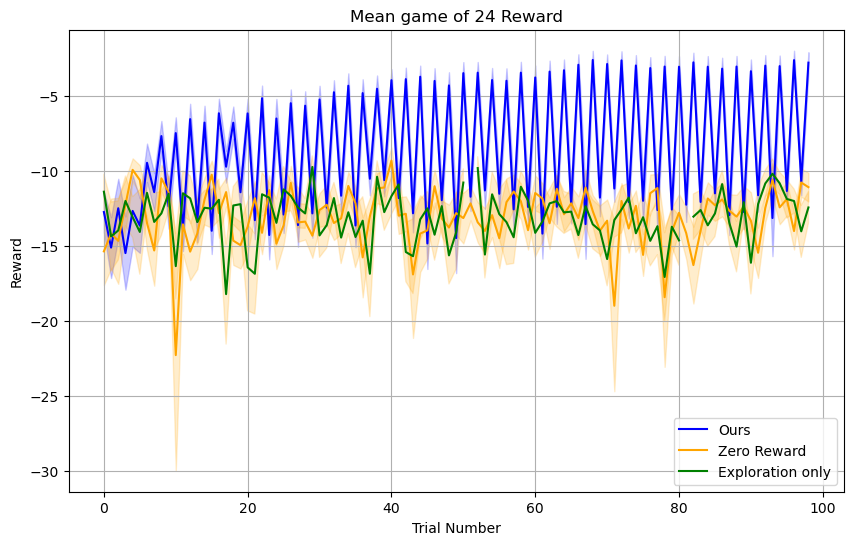

In [128]:

# path = "alpaca_game24_api/google/gemma-7b-it/100_mini_evalnum_45_n_200/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_same_base_evalnum_12_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_exploitation_same_base_evalnum_12_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/ICRL_no_reward_exploration_only_100_mini_evalnum_45_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/ICRL100_mini_evalnum_45_n_100/output_list.json"

running_max = False

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

path = "creative_writing_api/google/gemma-7b-it/best_of_n_same_base_evalnum_12_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_mini_evalnum_45_n_100/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_mini_evalnum_45_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/ICRL_no_reward_exploration_only_100_mini_evalnum_45_n_100/output_list.json"
# ### 3

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

second = 1
third = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Zero Reward')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='Exploration only')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='orange', alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean game of 24 Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

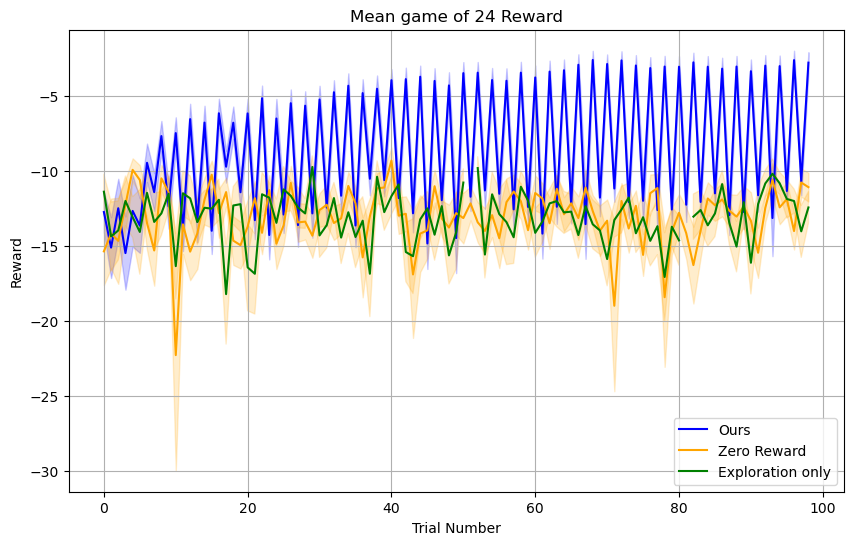

In [140]:

# path = "alpaca_game24_api/google/gemma-7b-it/100_mini_evalnum_45_n_200/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_same_base_evalnum_12_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_exploitation_same_base_evalnum_12_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/ICRL_no_reward_exploration_only_100_mini_evalnum_45_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/ICRL100_mini_evalnum_45_n_100/output_list.json"

running_max = False

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

path = "creative_writing_api/google/gemma-7b-it/best_of_n_same_base_evalnum_12_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_mini_evalnum_45_n_100/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_mini_evalnum_45_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/ICRL_no_reward_exploration_only_100_mini_evalnum_45_n_100/output_list.json"


# ### 3

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

second = 1
third = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Zero Reward')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='Exploration only')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='orange', alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean game of 24 Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

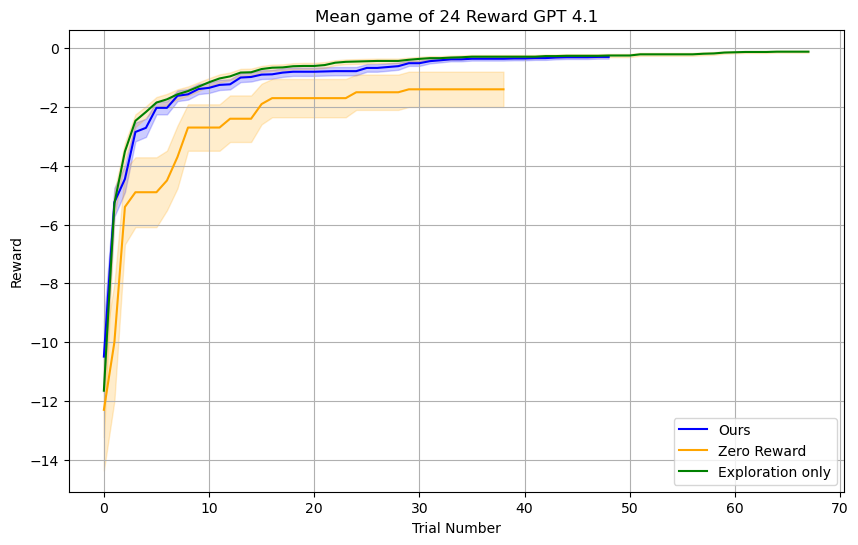

In [452]:

# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_ICRL_gpt4.1__evalnum_40_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/100_samples_ICRL__gpt4.1__evalnum_100_n_50/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/10_samples_ICRL_new_prompt__gpt4.1__evalnum_10_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/10_samples_ICRL_new_prompt__gpt4.1__evalnum_100_n_50/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/100_samples_ICRL__gpt4.1__evalnum_100_n_50/output_list.json"
running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row][0::] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# path = "alpaca_game24_api/google/gemma-7b-it/rejection_100_gpt4.1__evalnum_40_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/rejection_100_gpt4.1__evalnum_10_n_40/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])



path = "alpaca_game24_api/google/gemma-7b-it/100_no_reward_exploration_gpt4.1__evalnum_100_n_100/output_list.json"
path = "alpaca_game24_api/google/gemma-7b-it/100_no_reward_exploration_gpt4.1__evalnum_100_n_100/output_list.json"
# ### 3

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

second = 1
third = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Zero Reward')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'green', label='Exploration only')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='orange', alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean game of 24 Reward GPT 4.1')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

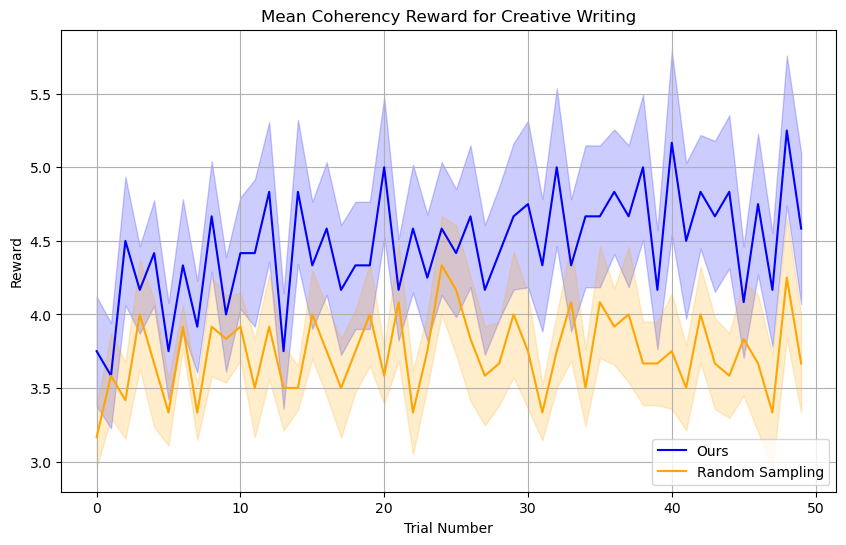

In [264]:

# path = "alpaca_game24_api/google/gemma-7b-it/100_mini_evalnum_45_n_200/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_same_base_evalnum_12_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_exploitation_same_base_evalnum_12_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_no_reward_exploration_only_100_mini_evalnum_45_n_100/output_list.json"

path = "creative_writing_api/google/gemma-7b-it/ICRL_same_base_evalnum_12_n_100/output_list.json"

running_max = False

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:51]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# path = "creative_writing_api/google/gemma-7b-it/best_of_n_same_base_evalnum_12_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/48_mini_evalnum_45_n_200/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/best_of_n_same_base_evalnum_12_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_exploitation_same_base_evalnum_12_n_100/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:51]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_zero_reward_100_mini_evalnum_45_n_100/output_list.json"
# path = ""


# ### 3

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Random Sampling')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Coherency Reward for Creative Writing')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:

# path = "alpaca_game24_api/google/gemma-7b-it/100_mini_evalnum_45_n_200/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_same_base_evalnum_12_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_exploitation_same_base_evalnum_12_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/ICRL_no_reward_exploration_only_100_mini_evalnum_45_n_100/output_list.json"

path = "creative_writing_api/google/gemma-7b-it/ICRL_gpt_4.1_same_base_evalnum_12_n_100/output_list.json"

running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:51]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

# path = "creative_writing_api/google/gemma-7b-it/best_of_n_same_base_evalnum_12_n_100/output_list.json"
# path = "alpaca_game24_api/google/gemma-7b-it/48_mini_evalnum_45_n_200/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/best_of_n_same_base_evalnum_12_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_simple_exploitation_same_base_evalnum_12_n_100/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/best_of_n_gpt_4.1_same_base_evalnum_12_n_100/output_list.json"
# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:51]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])



path = "creative_writing_api/google/gemma-7b-it/ICRL_exploration_only_gpt_4.1_same_base_evalnum_12_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_explore_and_exploit_gpt_4.1_same_base_evalnum_12_n_100/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_sorted_reward_gpt_4.1_same_base_evalnum_12_n_100/output_list.json"
# ### 3

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Random Sampling')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third: 
    plt.plot(x_3, mean_rewards_3, 'green', label='Exploration only')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='green', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Coherency Reward for Creative Writing')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

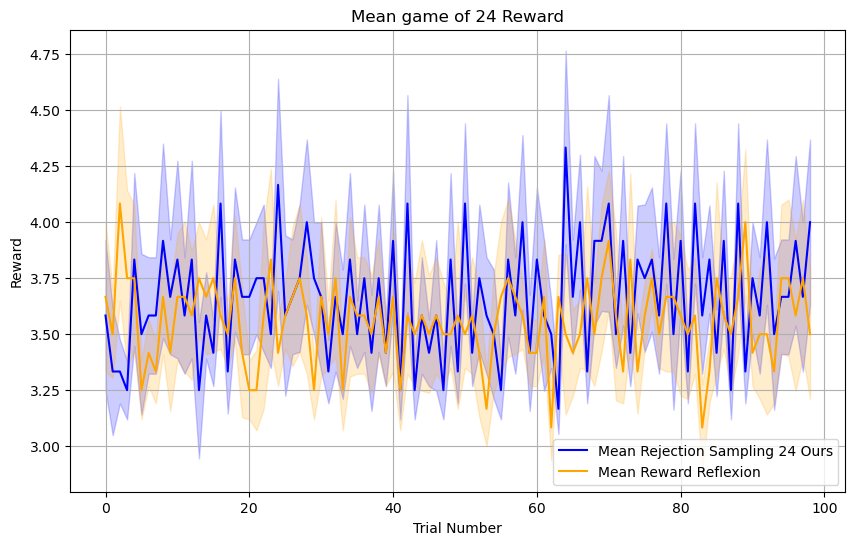

In [104]:

# path = "alpaca_game24_api/google/gemma-7b-it/100_mini_evalnum_45_n_200/output_list.json"
# path = "creative_writing_api/google/gemma-7b-it/ICRL_creative_writingvalid_comparison_evalnum_12_n_100/output_list.json"
path = "creative_writing_api/google/gemma-7b-it/ICRL_conservative_absolute_prompt_evalnum_12_n_100/output_list.json"

running_max = False

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

path = "creative_writing_api/google/gemma-7b-it/best_of_n_conservative_absolute_prompt_evalnum_12_n_100/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Rejection Sampling 24 Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean game of 24 Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

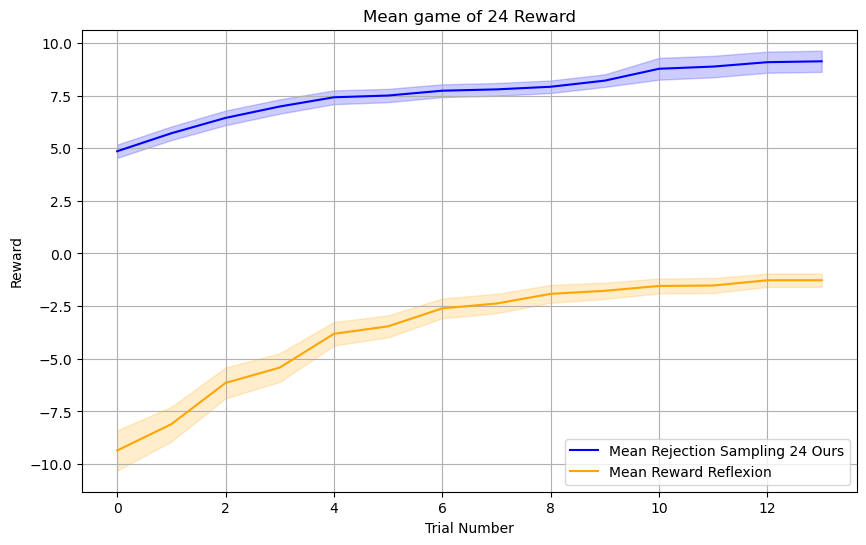

In [30]:

path = "alpaca_game24_api/google/gemma-7b-it/100_mini_evalnum_45_n_200/output_list.json"
path = "/sfs/weka/scratch/ks8vf/ICL/alpaca_game24_api/google/gemma-7b-it/ICRL100_mini_evalnum_45_n_100/output_list.json"
running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:48]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['gpt_eval_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:48]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)
# data = np.array([[x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Rejection Sampling 24 Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean game of 24 Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [24]:
# modified_data

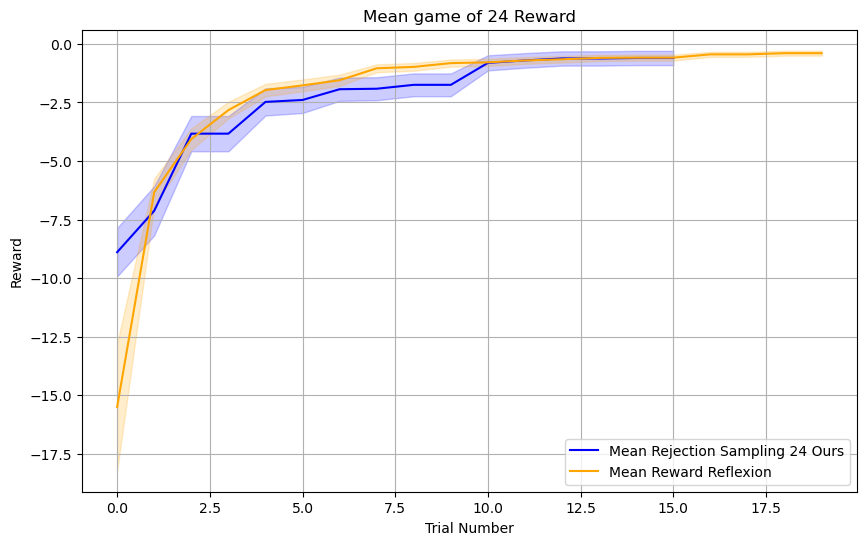

In [16]:

path = "alpaca_game24_api/google/gemma-7b-it/48_mini_evalnum_45_n_200/output_list.json"
running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:20]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])


path = "alpaca_game24_api/google/gemma-7b-it/100_mini_evalnum_45_n_200/output_list.json"

# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:20]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Rejection Sampling 24 Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean game of 24 Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()




In [ ]:

path = "alpaca_game24_api/google/gemma-7b-it/100_mini_evalnum_45_n_200/output_list.json"
running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:20]:
        reward_list.append(float(trial['gpt_eval_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:20]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Rejection Sampling 24 Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean game of 24 Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [4]:
path = "/sfs/weka/scratch/ks8vf/ICL/alpaca_game24_api/google/gemma-7b-it/rejection_200_words_start_low_evalnum_45_n_200/output_list.json"

path = "/sfs/weka/scratch/ks8vf/ICL/alpaca_game24_api/google/gemma-7b-it/_evalnum_45_n_20/output_list.json"
import json
with open(path, 'r') as f:
    output = json.load(f)

In [27]:
# output[2]

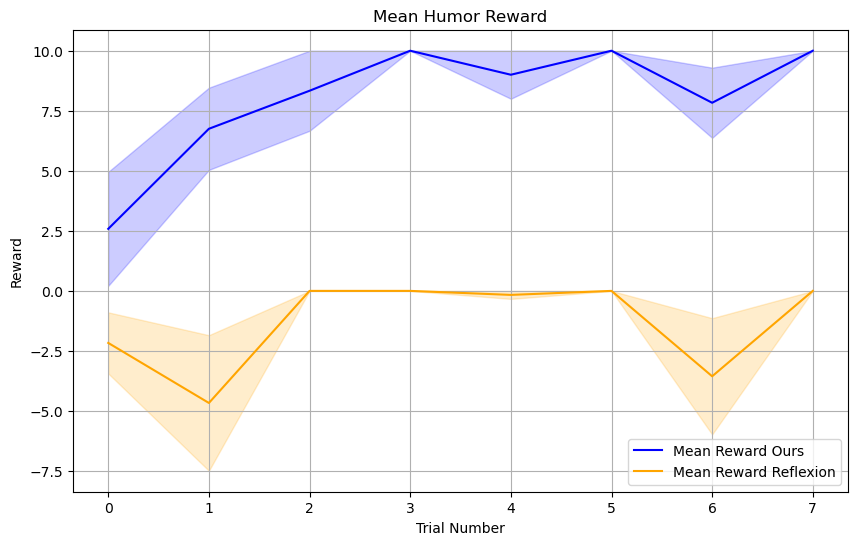

In [21]:
path = "/sfs/weka/scratch/ks8vf/ICL/alpaca_game24_api/google/gemma-7b-it/simple_12_evalnum_45_n_200/output_list.json"

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['gpt_eval_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

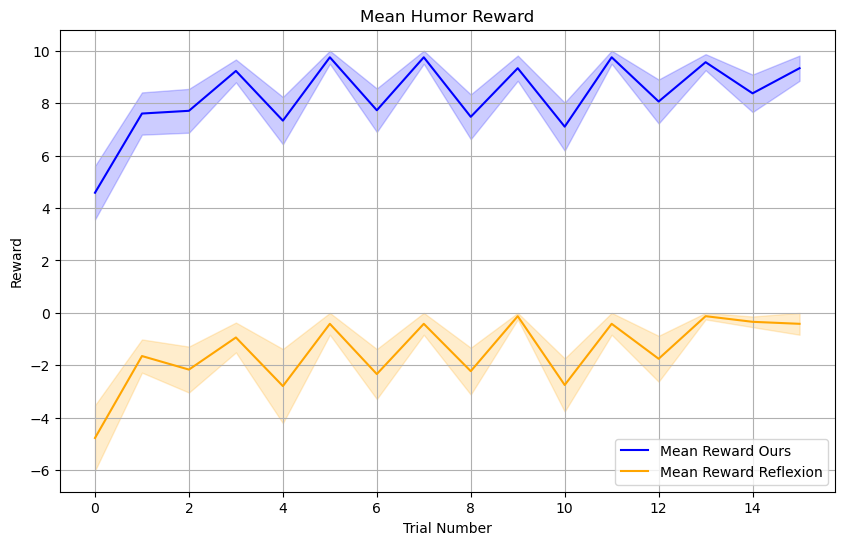

In [43]:
path = "/sfs/weka/scratch/ks8vf/ICL/alpaca_game24_api/google/gemma-7b-it/simple_48_evalnum_45_n_200/output_list.json"

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['gpt_eval_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [1]:
# path = "/sfs/weka/scratch/ks8vf/ICL/alpaca_game24_api/google/gemma-7b-it/rejection_nano_48_evalnum_45_n_200/output_list.json"

# import numpy as np
# import matplotlib.pyplot as plt

# import json
# with open(path, 'r') as f:
#     output = json.load(f)
    
# all_question_reward_list = []
# for question in output[:]:
#     reward_list = []
#     for trial in question[:]:
#         reward_list.append(float(trial['accuracy_reward']))
#     all_question_reward_list.append(reward_list)
# modified_data = [[ x for x in row] for row in all_question_reward_list]

# modified_data

# running_max = np.maximum.accumulate(modified_data, axis=1)

# modified_data

In [2]:
# running_max

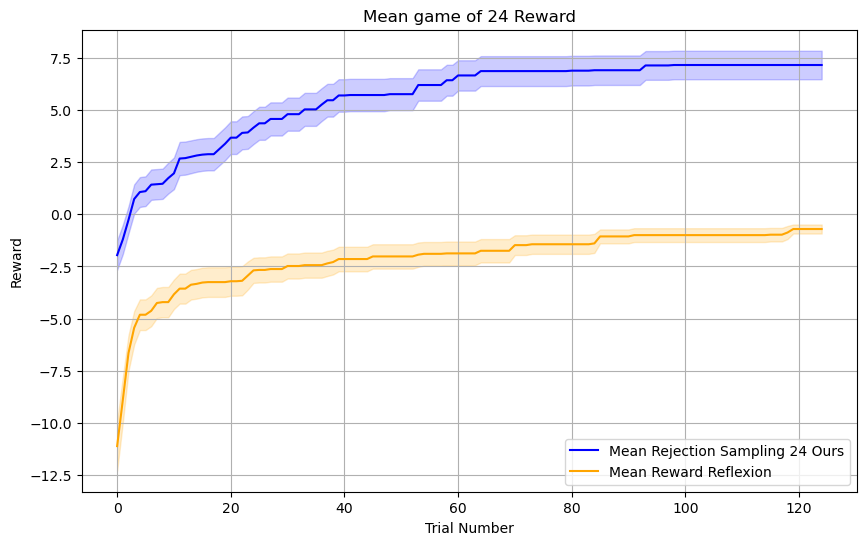

In [11]:
path = "/sfs/weka/scratch/ks8vf/ICL/alpaca_game24_api/google/gemma-7b-it/rejection_mini_48_evalnum_45_n_200/output_list.json"


path = "alpaca_game24_api/google/gemma-7b-it/rejection_simple_prompt_48_evalnum_45_n_200/output_list.json"
running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['gpt_eval_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Rejection Sampling 24 Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean game of 24 Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [2]:
# path = "alpaca_game24_api/google/gemma-7b-it/simple_mini_48_evalnum_45_n_200/output_list.json"


# running_max = True

# import numpy as np
# import matplotlib.pyplot as plt

# import json
# with open(path, 'r') as f:
#     output = json.load(f)
    
# all_question_reward_list = []
# for question in output[:]:
#     reward_list = []
#     for trial in question[:]:
#         reward_list.append(float(trial['gpt_eval_reward']))
#     all_question_reward_list.append(reward_list)
# modified_data = [[ x for x in row] for row in all_question_reward_list]
# ### Running max
# if running_max:
#     modified_data = np.maximum.accumulate(modified_data, axis=1)


# # None if x == -0.8 else
# # Assuming modified_data is already defined with None values for entries > 0.8
# all_question_reward_list = modified_data

# # Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# # Calculate the mean reward for each trial ignoring NaNs
# mean_rewards = np.nanmean(data, axis=0)

# # Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
# std_rewards = np.nanstd(data, axis=0, ddof=1)

# # For each trial, count the number of non-NaN values to compute the standard error
# n = np.sum(~np.isnan(data), axis=0)
# standard_error = std_rewards / np.sqrt(n)

# # Calculate lower and upper bounds (mean ± standard error)
# lower_bound = mean_rewards - standard_error
# upper_bound = mean_rewards + standard_error

# # Generate x values (trial indices)
# x = np.arange(data.shape[1])



# # ### Rejection 

# with open(path, 'r') as f:
#     output = json.load(f)
    
# all_question_reward_list = []
# for question in output[:]:
#     reward_list = []
#     for trial in question[:]:
#         reward_list.append(float(trial['accuracy_reward']))
#     all_question_reward_list.append(reward_list)
# modified_data = [[x for x in row] for row in all_question_reward_list]
# ### Running max
# if running_max:
#     modified_data = np.maximum.accumulate(modified_data, axis=1)

# # Assuming modified_data is already defined with None values for entries > 0.8
# all_question_reward_list = modified_data

# # Convert the list to a numpy array of floats, replacing None with np.nan
# data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# # Calculate the mean reward for each trial ignoring NaNs
# mean_rewards_reflexion = np.nanmean(data, axis=0)

# # Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
# std_rewards = np.nanstd(data, axis=0, ddof=1)

# # For each trial, count the number of non-NaN values to compute the standard error
# n = np.sum(~np.isnan(data), axis=0)
# standard_error = std_rewards / np.sqrt(n)

# # Calculate lower and upper bounds (mean ± standard error)
# lower_bound_reflexion = mean_rewards_reflexion - standard_error
# upper_bound_reflexion = mean_rewards_reflexion + standard_error

# # Generate x values (trial indices)
# x_reflexion = np.arange(data.shape[1])


# second = 1
# # Create the plot
# plt.figure(figsize=(10, 6))
# plt.plot(x, mean_rewards, 'b-', label='Mean Rejection Sampling 24 Ours')
# plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
# if second:
#     plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
#     plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
# plt.xlabel('Trial Number')
# plt.ylabel('Reward')
# plt.title('Mean Humor Reward')
# plt.legend(loc='lower right')
# plt.grid(True)
# plt.show()

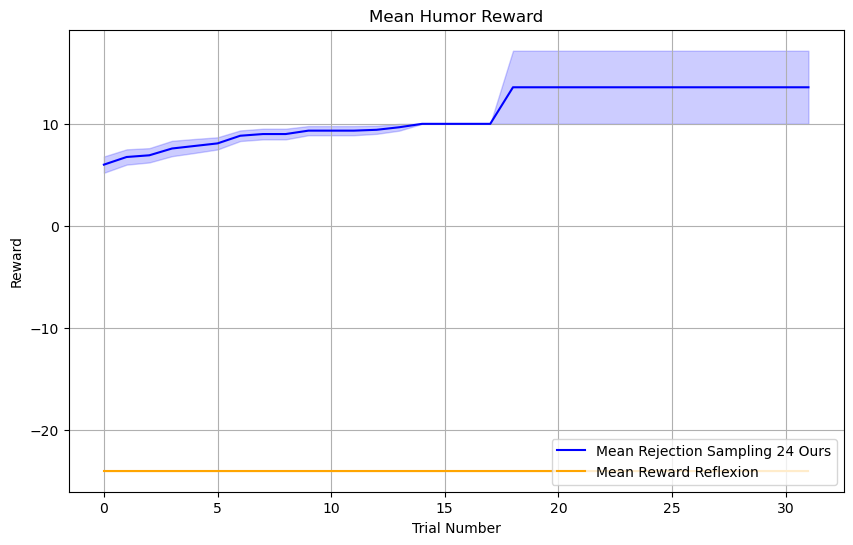

In [5]:
path = "alpaca_game24_api/google/gemma-7b-it/simple_12q_mini_48_evalnum_45_n_200/output_list.json"


running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['gpt_eval_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Rejection Sampling 24 Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

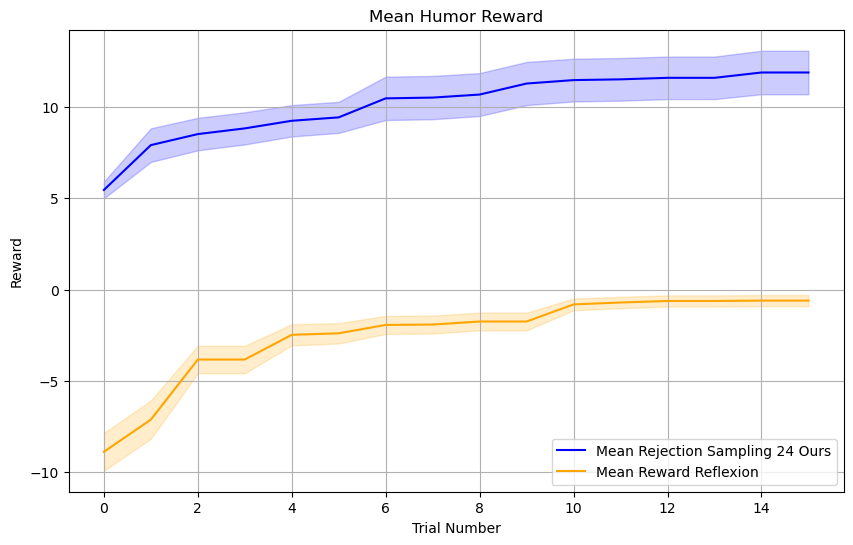

In [9]:
path = "alpaca_game24_api/google/gemma-7b-it/48_mini_evalnum_45_n_200/output_list.json"


running_max = True

import numpy as np
import matplotlib.pyplot as plt

import json
with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['gpt_eval_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)


# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open(path, 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[:]:
        reward_list.append(float(trial['accuracy_reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]
### Running max
if running_max:
    modified_data = np.maximum.accumulate(modified_data, axis=1)

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])


second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Rejection Sampling 24 Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [2]:


# # install matplotlib
# # !pip install matplotlib
# # Update numpy to a compatible version for matplotlib
# !pip install numpy>=1.15 --upgrade

# # After upgrading numpy, install matplotlib
# !pip install matplotlib

# # Import the required libraries
# import numpy as np
# import matplotlib.pyplot as plt

# # Verify numpy version
# print(f"NumPy version: {np.__version__}")


In [24]:
my_print(output[1][0]['answer'])

NameError: name 'long_text' is not defined

In [22]:
def my_print(x):
    for i in range(0, len(x), 70):
        print(x[i:i+70])

In [ ]:
import pickle
with open("intermediate_round.pkl", "rb") as f:
    c = pickle.load(f)

In [14]:
samples[0]

{'question': '4 5 6 10',
 'weak_demos': [{'prompt': '4 5 6 10', 'answer': '', 'reward': '-24.00'},
  {'prompt': '4 5 6 10', 'answer': '', 'reward': '-24.00'},
  {'prompt': '4 5 6 10', 'answer': '', 'reward': '-24.00'},
  {'prompt': '4 5 6 10', 'answer': '', 'reward': '-24.00'},
  {'prompt': '4 5 6 10', 'answer': '', 'reward': '-24.00'}],
 'output': [{'round': 0,
   'prompt': 'Use numbers and basic arithmetic operations (+ - * /) to obtain 24. Each step, you are only allowed to choose two of the remaining numbers to obtain a new number.\nInput: 4 4 6 8\nSteps:\n4 + 8 = 12 (left: 4 6 12)\n6 - 4 = 2 (left: 2 12)\n2 * 12 = 24 (left: 24)\nAnswer: (6 - 4) * (4 + 8) = 24\nInput: 2 9 10 12\nSteps:\n12 * 2 = 24 (left: 9 10 24)\n10 - 9 = 1 (left: 1 24)\n24 * 1 = 24 (left: 24)\nAnswer: (12 * 2) * (10 - 9) = 24\nInput: 4 9 10 13\nSteps:\n13 - 10 = 3 (left: 3 4 9)\n9 - 3 = 6 (left: 4 6)\n4 * 6 = 24 (left: 24)\nAnswer: 4 * (9 - (13 - 10)) = 24\nInput: 1 4 8 8\nSteps:\n8 / 4 = 2 (left: 1 2 8)\n1 + 2 

IC RL avg max reward:     8.412698412698413
rejection avg max reward: 8.642857142857142


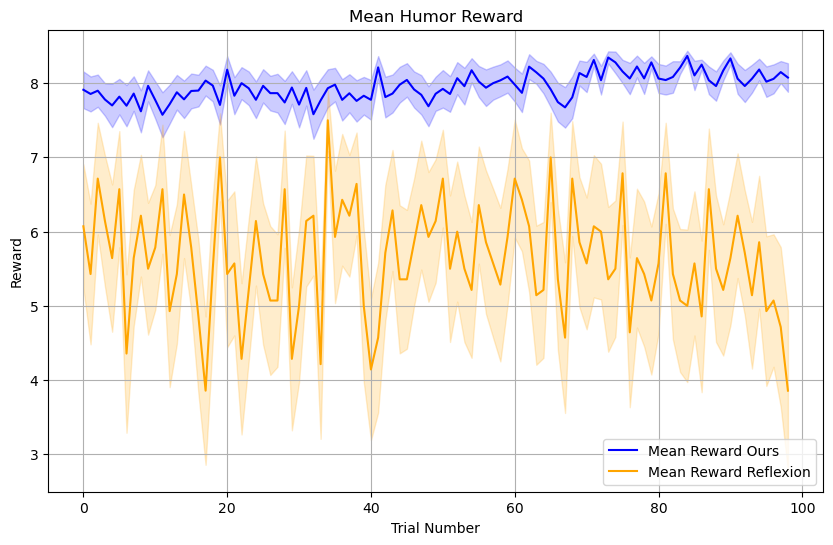

In [30]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_humor/google/gemma-7b-it/two_rewards_evalnum_200_n_100/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("IC RL avg max reward:    ", np.nanmean(result))




# ### Rejection 

with open('alpaca_humor/google/gemma-7b-it/rejection_two_rewards4.1mini_n_100/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("rejection avg max reward:", np.nanmean(result))

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

8.642857142857142

IC RL avg max reward:     8.714285714285714
rejection avg max reward: 8.73015873015873


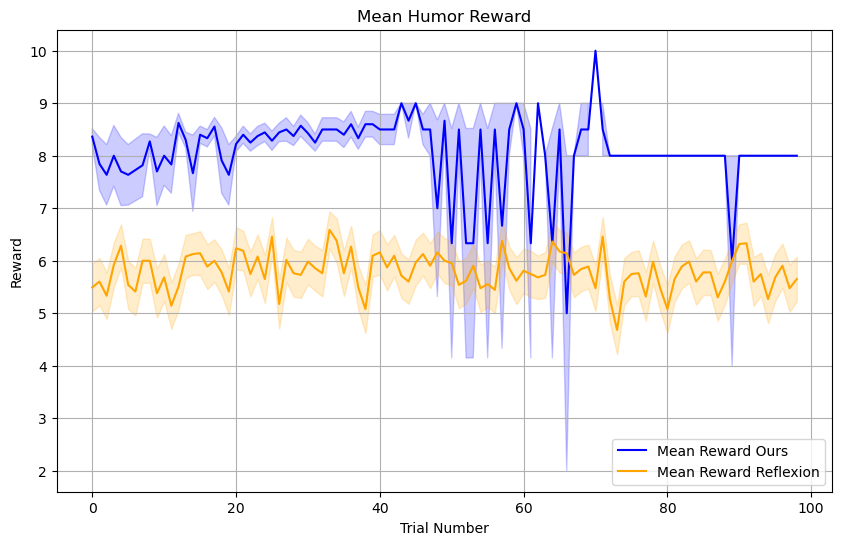

In [24]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_humor/google/gemma-7b-it/two_rewards4.1mini_n_100/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("IC RL avg max reward:    ", np.nanmean(result))




# ### Rejection 

with open('alpaca_humor/google/gemma-7b-it/rejection_two_rewards_evalnum_200_n_100/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("rejection avg max reward:", np.nanmean(result))

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
ICL/

IC RL avg max reward:     3.4530000000000003
rejection avg max reward: 2.256542857142857


/tmp/ipykernel_355648/1542616172.py:40: RuntimeWarning: All-NaN slice encountered
  result = np.nanmax(d, axis=1)


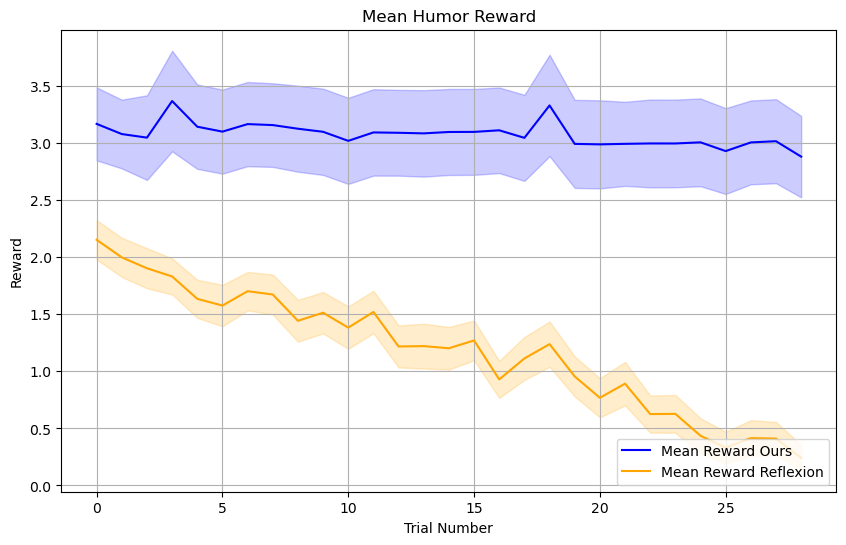

In [27]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_rouge/google/gemma-7b-it/instruction_n_30/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("IC RL avg max reward:    ", np.nanmean(result))




# ### Rejection 

with open('alpaca_rouge/meta-llama/Meta-Llama-3-8B-Instruct/instruction_n_30/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("rejection avg max reward:", np.nanmean(result))

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
ICL/

IC RL avg max reward:     4.065416666666667
rejection avg max reward: 2.256542857142857


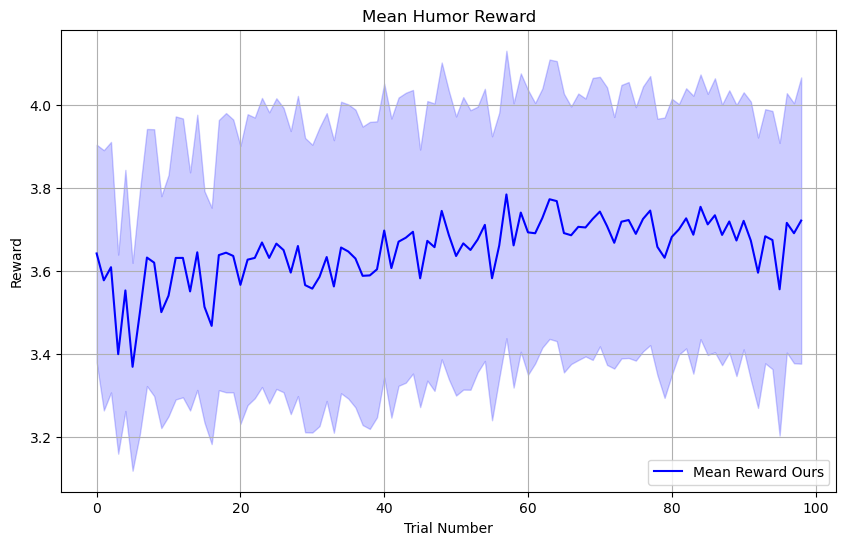

In [32]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_rouge_api/gpt-4.1-mini/no_instruction_100/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("IC RL avg max reward:    ", np.nanmean(result))




# ### Rejection 

with open('alpaca_rouge/meta-llama/Meta-Llama-3-8B-Instruct/instruction_n_30/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("rejection avg max reward:", np.nanmean(result))

second = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
ICL/alpaca_rouge_api/gpt-4.1-mini/no_instruction_500/output_list.json

IC RL avg max reward:     3.7678333333333325
rejection avg max reward: 2.256542857142857


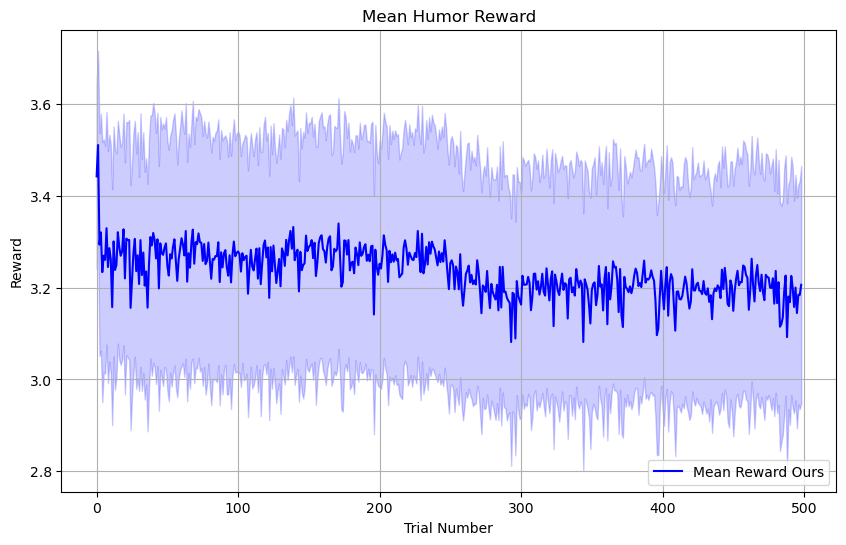

In [33]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_rouge_api/gpt-4.1-mini/no_instruction_500/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("IC RL avg max reward:    ", np.nanmean(result))




# ### Rejection 

with open('alpaca_rouge/meta-llama/Meta-Llama-3-8B-Instruct/instruction_n_30/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("rejection avg max reward:", np.nanmean(result))

second = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
ICL/alpaca_inv_rouge_api/meta-llama/Meta-Llama-3-8B-Instruct/instruction_n_30/output_list.json

IC RL avg max reward:     0.8514166666666666
rejection avg max reward: 2.256542857142857


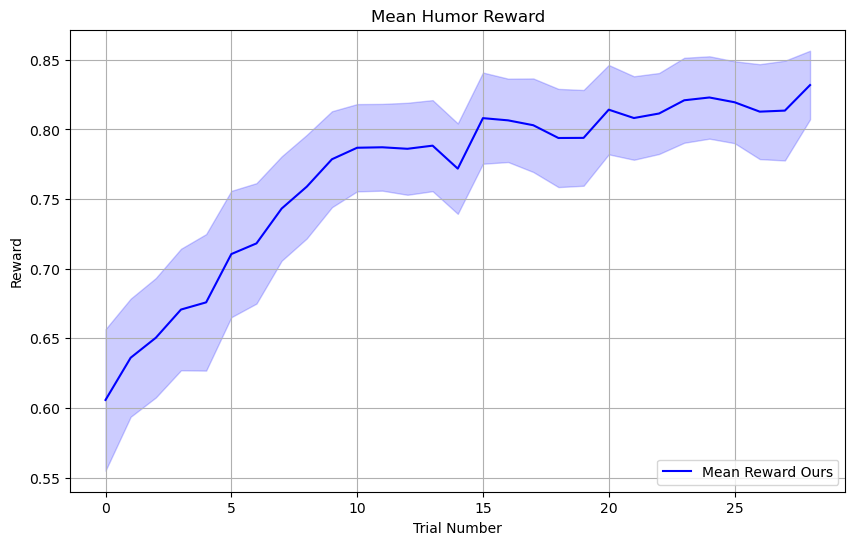

In [34]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_inv_rouge_api/meta-llama/Meta-Llama-3-8B-Instruct/instruction_n_30/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("IC RL avg max reward:    ", np.nanmean(result))




# ### Rejection 

with open('alpaca_rouge/meta-llama/Meta-Llama-3-8B-Instruct/instruction_n_30/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("rejection avg max reward:", np.nanmean(result))

second = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
ICL/

IC RL avg max reward:     3.9620833333333336
rejection avg max reward: 4.592833333333332


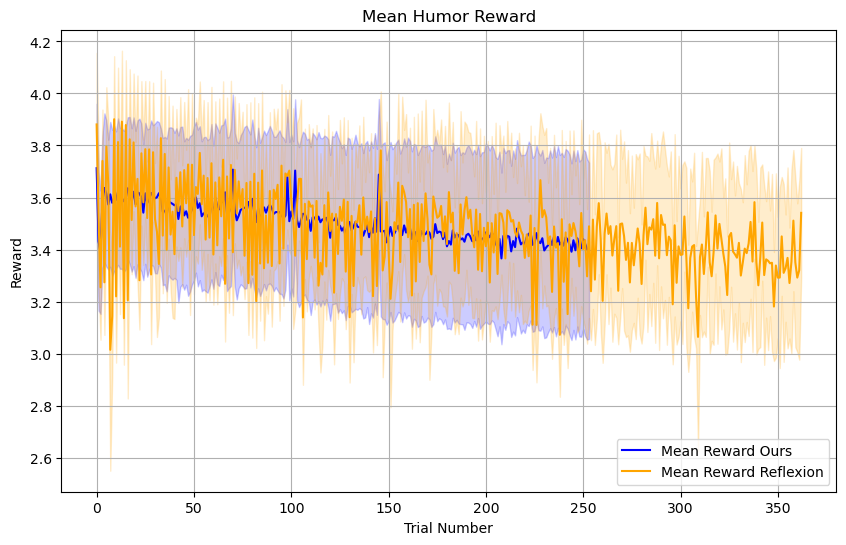

In [5]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_rouge_api/gpt-4.1-mini/ucb_exploitation_instruction_500/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("IC RL avg max reward:    ", np.nanmean(result))




# ### Rejection 

with open('alpaca_rouge_api/gpt-4.1-mini/ucb_instruction_500/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("rejection avg max reward:", np.nanmean(result))

second = 1
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

IC RL avg max reward:     4.5705
rejection avg max reward: 4.592833333333332


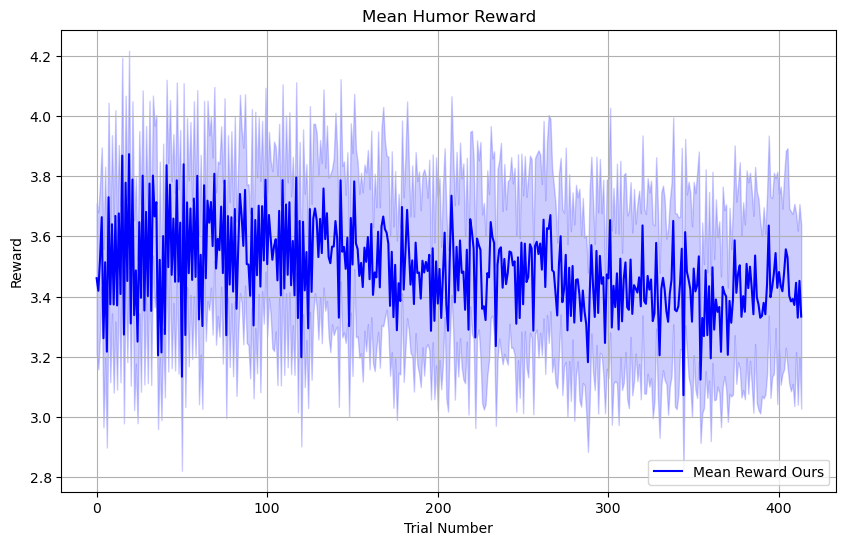

In [6]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_rouge_api/gpt-4.1-mini/with_instruction_500/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row] for row in all_question_reward_list]
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("IC RL avg max reward:    ", np.nanmean(result))




# ### Rejection 

with open('alpaca_rouge_api/gpt-4.1-mini/ucb_instruction_500/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

d = np.asarray(modified_data, dtype=float)
result = np.nanmax(d, axis=1)
print("rejection avg max reward:", np.nanmean(result))

second = 0
# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [12]:
# modified_data

In [13]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_rouge_api/gpt-4.1-mini/epsion_greedy_recall_instruction_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row] for row in all_question_reward_list]

modified_data = modified_data[1::2]

In [25]:
with open('alpaca_rouge_api/gpt-4.1-mini/epsion_greedy_recall_instruction_200/output_list.json', 'r') as f:
    output = json.load(f)
    
output[0][-3]['answer']

'\nCogging torque is a type of torque ripple occurring in permanent magnet motors, caused by the magnetic interaction between the rotor’s permanent magnets and the stator slots or teeth. This interaction generates preferred rotor positions where the magnetic reluctance is minimized, causing the rotor to resist rotation and tend to align with these stable equilibrium points. As the rotor moves between these positions, the motor experiences a jerky or non-uniform motion, especially at low speeds, resulting in pulsating torque fluctuations that produce vibrations, noise, and acoustic disturbances.\n\nThis effect arises because the magnetic flux naturally prefers paths of least reluctance through the stator teeth, leading to periodic torque variations and uneven rotation. Cogging torque reduces the smoothness, efficiency, and operational precision of the motor by generating mechanical vibration and acoustic noise, thereby degrading performance and control accuracy. It manifests as a flutte

In [24]:
output[0][-3]['reward']

'4.783'

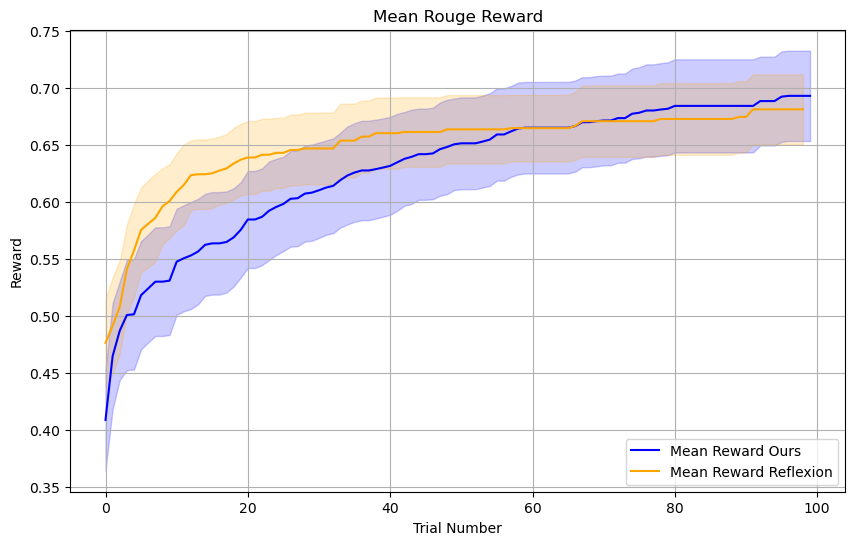

In [69]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_rouge_api/gpt-4.1-mini/epsion_greedy_recall_instruction_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row][0::2] for row in all_question_reward_list]

def running_max_row(row):
    result = []
    current = float('-inf')
    for x in row:
        if x is not None:
            current = max(current, x)
        # if we still haven't seen any number, you might prefer None instead of -inf:
        result.append(current if current != float('-inf') else None)
    return result

modified_data = [running_max_row(row) for row in modified_data]

# modified_data = modified_data
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)



# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open('alpaca_rouge_api/gpt-4.1-mini/recall_reflexion_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row][1::2] for row in all_question_reward_list]

def running_max_row(row):
    result = []
    current = float('-inf')
    for x in row:
        if x is not None:
            current = max(current, x)
        # if we still haven't seen any number, you might prefer None instead of -inf:
        result.append(current if current != float('-inf') else None)
    return result

modified_data = [running_max_row(row) for row in modified_data]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

second = 1

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards/10, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound/10, upper_bound/10, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion/10, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion/10, upper_bound_reflexion/10, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Rouge Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

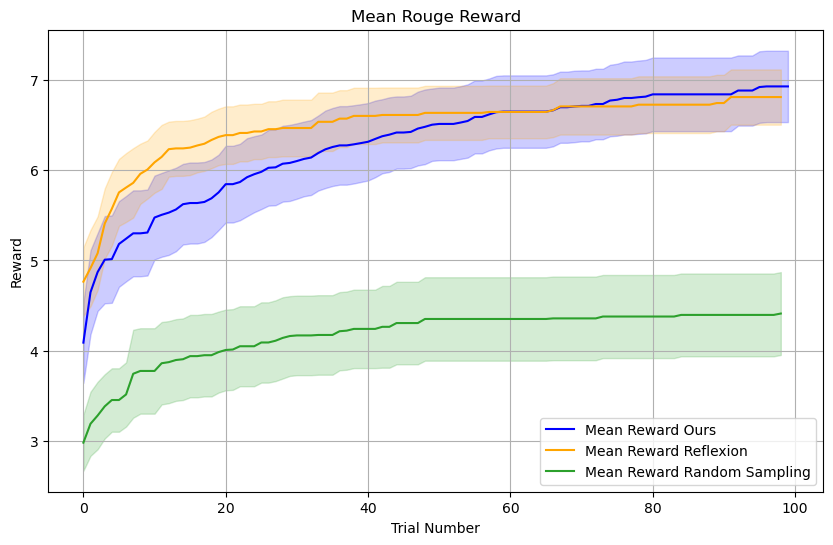

In [71]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_rouge_api/gpt-4.1-mini/epsion_greedy_recall_instruction_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row][0::2][:] for row in all_question_reward_list]

def running_max_row(row):
    result = []
    current = float('-inf')
    for x in row:
        if x is not None:
            current = max(current, x)
        # if we still haven't seen any number, you might prefer None instead of -inf:
        result.append(current if current != float('-inf') else None)
    return result

modified_data = [running_max_row(row) for row in modified_data]

# modified_data = modified_data
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)



# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open('alpaca_rouge_api/gpt-4.1-mini/recall_reflexion_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row][1::2][:] for row in all_question_reward_list]

def running_max_row(row):
    result = []
    current = float('-inf')
    for x in row:
        if x is not None:
            current = max(current, x)
        # if we still haven't seen any number, you might prefer None instead of -inf:
        result.append(current if current != float('-inf') else None)
    return result

modified_data = [running_max_row(row) for row in modified_data]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

second = 1


# ### Rejection sampling 

with open('alpaca_rouge_api/gpt-4.1-mini/rejection_sampling_recall_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row][1::2][:] for row in all_question_reward_list]

def running_max_row(row):
    result = []
    current = float('-inf')
    for x in row:
        if x is not None:
            current = max(current, x)
        # if we still haven't seen any number, you might prefer None instead of -inf:
        result.append(current if current != float('-inf') else None)
    return result

modified_data = [running_max_row(row) for row in modified_data]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

second = 1
third = 1

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'tab:green', label='Mean Reward Random Sampling')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='tab:green', alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Rouge Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

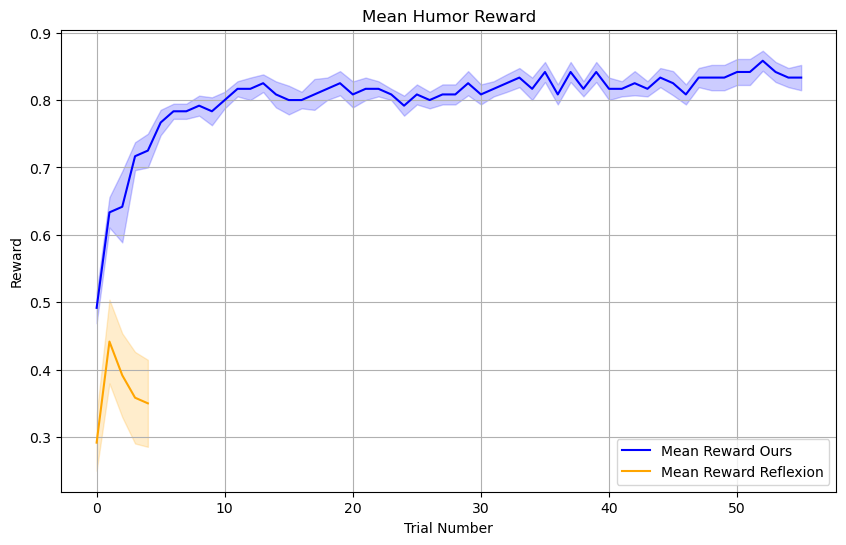

In [36]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_humor/google/gemma-7b-it/two_rewards_evalnum_45_n_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row][0::2] for row in all_question_reward_list]

# modified_data = modified_data
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)



# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open('alpaca_humor_api/google/gemma-7b-it/reflexion_evalnum_45_n_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row][1::2] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

second = 1

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards/10, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound/10, upper_bound/10, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion/10, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion/10, upper_bound_reflexion/10, color='orange', alpha=0.2)
plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

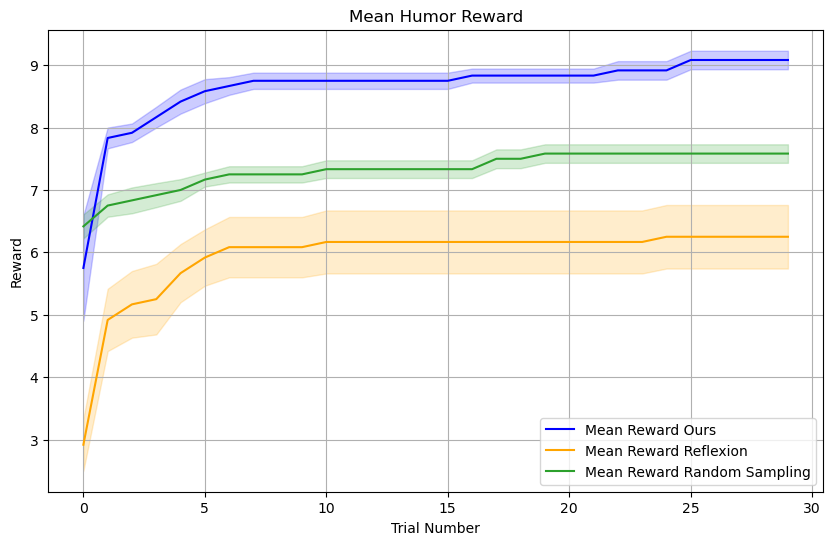

In [72]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('alpaca_humor_api/google/gemma-7b-it/two_rewards_evalnum_45_n_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row][0::2][:30] for row in all_question_reward_list]

def running_max_row(row):
    result = []
    current = float('-inf')
    for x in row:
        if x is not None:
            current = max(current, x)
        # if we still haven't seen any number, you might prefer None instead of -inf:
        result.append(current if current != float('-inf') else None)
    return result

modified_data = [running_max_row(row) for row in modified_data]

# modified_data = modified_data
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)



# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open('alpaca_humor_api/google/gemma-7b-it/reflexion_evalnum_45_n_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row][1::2][:30] for row in all_question_reward_list]

def running_max_row(row):
    result = []
    current = float('-inf')
    for x in row:
        if x is not None:
            current = max(current, x)
        # if we still haven't seen any number, you might prefer None instead of -inf:
        result.append(current if current != float('-inf') else None)
    return result

modified_data = [running_max_row(row) for row in modified_data]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

second = 1


# ### Rejection sampling 

with open('alpaca_humor_api/google/gemma-7b-it/rejection_200_words_evalnum_45_n_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row][1::2][:30] for row in all_question_reward_list]

def running_max_row(row):
    result = []
    current = float('-inf')
    for x in row:
        if x is not None:
            current = max(current, x)
        # if we still haven't seen any number, you might prefer None instead of -inf:
        result.append(current if current != float('-inf') else None)
    return result

modified_data = [running_max_row(row) for row in modified_data]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

second = 1
third = 1

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'tab:green', label='Mean Reward Random Sampling')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='tab:green', alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
ICL/

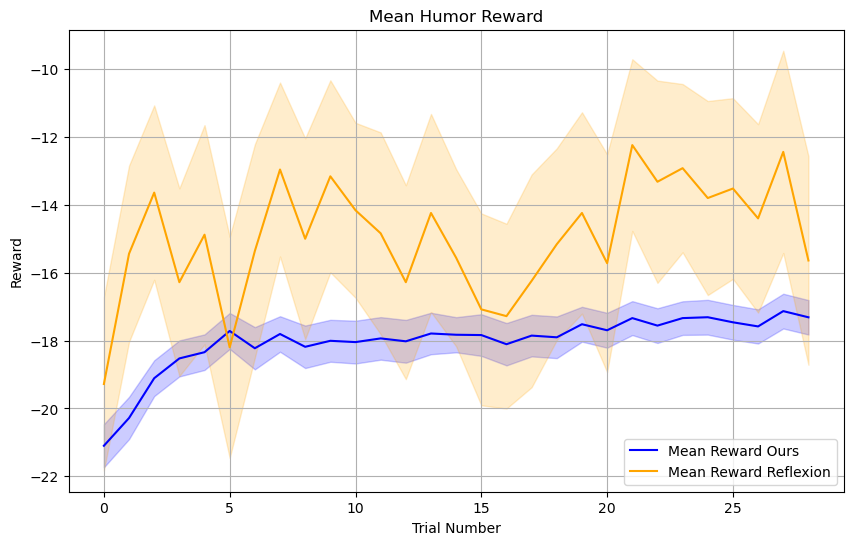

In [6]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('gsm_digits/meta-llama/Meta-Llama-3-8B-Instruct/n_30/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row][:30] for row in all_question_reward_list]

# modified_data = modified_data
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else -x for x in row] for row in all_question_reward_list], dtype=float)



# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open('gsm_digits/meta-llama/Meta-Llama-3-8B-Instruct/reflexion_reward_10_n_30/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[-x for x in row][:30] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

second = 1


# ### Rejection sampling 

with open('alpaca_humor_api/google/gemma-7b-it/rejection_200_words_evalnum_45_n_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row][1::2][:30] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

second = 1
third = 0

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'tab:green', label='Mean Reward Random Sampling')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='tab:green', alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
ICL/

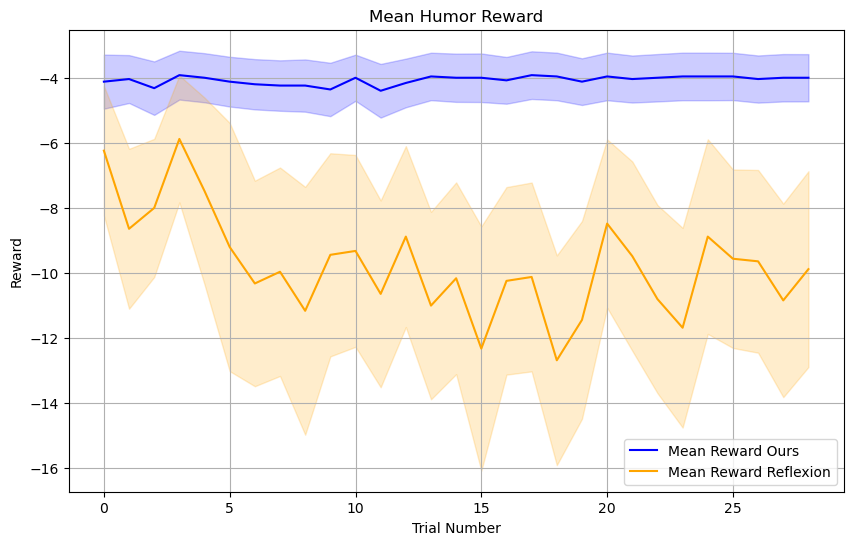

In [7]:
import numpy as np
import matplotlib.pyplot as plt

import json
with open('gsm_digits/meta-llama/Meta-Llama-3-8B-Instruct/task_promptreward_10_n_30/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[ None if x == 0.00 or x ==0.00 else x for x in row][:30] for row in all_question_reward_list]

# modified_data = modified_data
# None if x == -0.8 else
# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else -x for x in row] for row in all_question_reward_list], dtype=float)



# Calculate the mean reward for each trial ignoring NaNs
mean_rewards = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound = mean_rewards - standard_error
upper_bound = mean_rewards + standard_error

# Generate x values (trial indices)
x = np.arange(data.shape[1])



# ### Rejection 

with open('gsm_digits/meta-llama/Meta-Llama-3-8B-Instruct/reflexion_reward_10_n_30/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[-x for x in row][:30] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_reflexion = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_reflexion = mean_rewards_reflexion - standard_error
upper_bound_reflexion = mean_rewards_reflexion + standard_error

# Generate x values (trial indices)
x_reflexion = np.arange(data.shape[1])

second = 1


# ### Rejection sampling 

with open('alpaca_humor_api/google/gemma-7b-it/rejection_200_words_evalnum_45_n_200/output_list.json', 'r') as f:
    output = json.load(f)
    
all_question_reward_list = []
for question in output[:]:
    reward_list = []
    for trial in question[1:]:
        reward_list.append(float(trial['reward']))
    all_question_reward_list.append(reward_list)
modified_data = [[x for x in row][1::2][:30] for row in all_question_reward_list]

# Assuming modified_data is already defined with None values for entries > 0.8
all_question_reward_list = modified_data

# Convert the list to a numpy array of floats, replacing None with np.nan
data = np.array([[np.nan if x is None else x for x in row] for row in all_question_reward_list], dtype=float)

# Calculate the mean reward for each trial ignoring NaNs
mean_rewards_3 = np.nanmean(data, axis=0)

# Calculate the standard deviation (sample std with ddof=1) ignoring NaNs
std_rewards = np.nanstd(data, axis=0, ddof=1)

# For each trial, count the number of non-NaN values to compute the standard error
n = np.sum(~np.isnan(data), axis=0)
standard_error = std_rewards / np.sqrt(n)

# Calculate lower and upper bounds (mean ± standard error)
lower_bound_3 = mean_rewards_3 - standard_error
upper_bound_3 = mean_rewards_3 + standard_error

# Generate x values (trial indices)
x_3 = np.arange(data.shape[1])

second = 1
third = 0

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, mean_rewards, 'b-', label='Mean Reward Ours')
plt.fill_between(x, lower_bound, upper_bound, color='blue', alpha=0.2)
if second:
    plt.plot(x_reflexion, mean_rewards_reflexion, 'orange', label='Mean Reward Reflexion')
    plt.fill_between(x_reflexion, lower_bound_reflexion, upper_bound_reflexion, color='orange', alpha=0.2)
if third:
    plt.plot(x_3, mean_rewards_3, 'tab:green', label='Mean Reward Random Sampling')
    plt.fill_between(x_3, lower_bound_3, upper_bound_3, color='tab:green', alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Reward')
plt.title('Mean Humor Reward')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()